# Functional Geostatistics of resting-state EEG spectra — v23.1

English notebook. Markdown cells are short headers; explanations live in code comments.
Outputs (figures, CSV tables, LaTeX tables and `results_macros.tex`) are written to `OUT_DIR`
so that the manuscript (`\input{results_macros.tex}`) is updated automatically after a full run.

**v23 changes (co-author review, A. Jaramillo-Jimenez — AJJ; and A. F. Ochoa-Muñoz — AO).**
Numbers in brackets refer to the comment index in the annotated PDF (AJJ #1-111).

**v23.1 (after the first full run):** (i) eyes-closed/eyes-open markers located after the end of the
EDF are ignored (they caused `tmin > tmax` errors in ~100 recordings; errors are not cached, so only
those recordings are reprocessed); (ii) the electrode adjacency is symmetrized across hemispheres;
(iii) figure layout fixes (F1, F3 log scale, F4 colour bars, F6 masked display); (iv) extra macros.

| Area | Change | Comments |
|---|---|---|
| Events | New audit of the full event-label vocabulary (photic stimulation, montage changes, which event ends each eyes-closed block) | AJJ #11, #13 |
| Inclusion | Subjects with < 60 s of eyes-closed (EC) signal are excluded **before** preprocessing, and the filter is **repeated after** preprocessing (>= 15 clean 4-s epochs = 60 s) | AJJ #26, #27 |
| Epochs | Same number of epochs for every subject (N = 15, 60 s); the epochs are chosen with scorEpochs (Fraschini et al., 2022), re-implemented here because the package is not on PyPI | AJJ #27 |
| Artifacts | Global autoreject threshold before ICA (Picard, extended, ortho=False) + MNE-ICALabel ("brain" kept), then **autoreject (local)** after ICA, replacing the all-channel peak-to-peak / flatline rule | AJJ #30, #31, #32, #34 |
| PSD | `psd_array_multitaper(bandwidth=1.0)` (full bandwidth 1 Hz, NW = 2, ±0.5 Hz smoothing) as primary; MNE default (2 Hz) kept as sensitivity | AJJ #36 |
| Geometry | Inter-electrode distance = **great-circle distance (cm)** on the sphere fitted to the 3-D standard_1020 template (primary); 3-D chord and the former normalized 2-D topomap distance kept as sensitivity analyses; lag-bin pair counts reported | AJJ #46 |
| Adjacency | Electrode adjacency = spherical Delaunay triangulation of the 3-D positions (convex hull), frozen, plotted and compared with `mne.channels.find_ch_adjacency` | AJJ #97 |
| Range | Raw `a` is never compared across models. All models are converted to the **practical range h95** (distance at 95 % of the partial sill; Matérn solved numerically). h95 is flagged *not identifiable* when it exceeds the largest observed lag or the fit hits a bound | AJJ #88, review file |
| Model | One **common** variogram model for all groups (lowest pooled AICc), instead of a different "best" model per group; per-group best models moved to the supplement | AJJ #88 |
| Endpoints | Primary subject-level endpoints are **observed-domain** summaries (area under the empirical variogram over the sampled lags; short-lag semivariance over adjacent electrodes); model sill and h95 are secondary | review file |
| Sensor level | Eq. 15 (mean dissimilarity of a sensor with **all** others) replaced by the **neighbourhood semivariance** (1/2 mean squared dissimilarity with adjacent electrodes) | AJJ #46, review file |
| Inference | Hand-written cluster test replaced by `mne.stats.permutation_cluster_test` (cluster-mass and TFCE); 2-D inputs (subjects x channels) shown as topoplots, 3-D inputs (subjects x frequency x channels, age-residualized log-PSD) shown as F heatmaps | AJJ #61, #62, #78, #108 |
| Effect sizes | epsilon^2 (Kruskal-Wallis), Cliff's delta (pairwise), Cohen's d for age; p-values are reported, not "highly significant" | AJJ #83 |
| Figures | Three independent `sphere` parameters (ROI diagram, topomaps, adjacency graph); combined sample/representation panel; violin + points + black median; topoplot grids (values -> differences -> statistics); no null-distribution figure | AJJ #64, #70, #81, #86, #96, #100, #106 |
| Wasserstein / Fisher-Rao | Explicit back-transform log10-PSD -> linear PSD -> normalized density, with assertions (positivity, unit mass, no double squaring) | review file |
| Age | Functional age residualization kept; sensitivity restricted to the common age support of the three groups and to age-matched subsamples | review file |
| Supplement | ROI analyses, model-comparison (Friedman, % best model), per-electrode FDR tables, alternative metrics, classical-qEEG benchmark | AJJ #69, #71, #72, #87, #90, #93, #102, #107 |

In [1]:
# Colab: install dependencies (onnxruntime is the lightweight ICLabel backend).
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "scikit-fda", "mne", "mne-icalabel",
                    "python-picard", "autoreject", "onnxruntime"], check=False)

In [2]:
import os, glob, json, re, pickle, warnings, itertools
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy import sparse
from scipy.optimize import curve_fit, brentq
from scipy.spatial import ConvexHull
from scipy.signal import welch
from scipy.stats import kruskal, mannwhitneyu, spearmanr, friedmanchisquare, chi2_contingency
from scipy.integrate import cumulative_trapezoid
from scipy.special import kv as _kv, gamma as _gamma_fn
import mne
from mne.time_frequency import psd_array_multitaper
from mne.stats import permutation_cluster_test, ttest_ind_no_p, combine_adjacency
from sklearn.preprocessing import SplineTransformer
from tqdm.auto import tqdm
from joblib import Parallel, delayed
from skfda.representation.basis import BSplineBasis, FourierBasis
from skfda.misc.operators import gram_matrix, LinearDifferentialOperator

np.set_printoptions(suppress=True)
mne.set_log_level("ERROR")
warnings.filterwarnings("ignore", category=RuntimeWarning)
_trapz = getattr(np, "trapezoid", None) or np.trapz

In [3]:
# Google Drive (Colab only). Locally, set the environment variable CAUEEG_BASE_DIR instead.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass

Mounted at /content/drive


## 1. Configuration

In [4]:
BASE_DIR = os.environ.get("CAUEEG_BASE_DIR",
                          "/content/drive/MyDrive/Carpeta_Doctorado/data_completa/caueeg-dataset")
EDF_DIR = os.path.join(BASE_DIR, "signal", "edf")
EVENT_DIR = os.path.join(BASE_DIR, "event")
DEMENTIA_JSON = os.path.join(BASE_DIR, "dementia-no-overlap.json")
OUT_DIR = os.environ.get("FDA_OUT_DIR", os.path.join(BASE_DIR, "results_v23"))
FIG_DIR, TAB_DIR = os.path.join(OUT_DIR, "figures"), os.path.join(OUT_DIR, "tables")
SUBJ_CACHE_DIR = os.path.join(BASE_DIR, "cache_v23_subjects")   # one pickle per subject (resumable)
for d in (OUT_DIR, FIG_DIR, TAB_DIR, SUBJ_CACHE_DIR):
    os.makedirs(d, exist_ok=True)

EYES_CLOSED_KEYWORDS = ["eyes closed", "eye closed"]
EYES_OPEN_KEYWORDS = ["eyes open", "eye open"]

# ---- Inclusion and epoching (AJJ #26-27) ----
WIN_SEC = 4.0             # epoch length (s)
MIN_EC_SEC = 60.0         # >= 1 min of eyes-closed signal before preprocessing
N_EPOCHS_EQUAL = int(round(MIN_EC_SEC / WIN_SEC))   # 15 epochs (60 s) per subject after preprocessing
TARGET_SFREQ = 128.0

# ---- Filtering / ICA / autoreject (AJJ #30-34) ----
FILTER_L_FREQ, FILTER_H_FREQ = 1.0, 45.0      # analysis band-pass
ICA_FIT_HIGH_FREQ = 99.0                      # ICLabel was trained on 1-100 Hz data
ICA_METHOD = "picard"
ICA_FIT_PARAMS = dict(ortho=False, extended=True)   # Picard settings equivalent to extended Infomax
ICA_RANDOM_STATE = 97
ICLABEL_KEEP = ("brain",)                     # components kept; everything else is removed
AR_N_INTERPOLATE = np.array([1, 2, 4])        # autoreject (local) grid, 19-channel montage
AR_CONSENSUS = np.linspace(0.1, 1.0, 10)
AR_CV = 5
AR_RANDOM_STATE = 42

# ---- Spectral estimation (AJJ #36) ----
FMIN, FMAX = 1.0, 30.0
PSD_BANDWIDTH = 1.0         # full bandwidth (Hz): +/-0.5 Hz smoothing, NW = T*B/2 = 2, ~3 tapers
PSD_BANDWIDTH_SENS = 2.0    # former MNE default (8/T) -> sensitivity analysis
PSD_ADAPTIVE, PSD_LOW_BIAS, PSD_NORMALIZATION = False, True, "length"
SCOREPOCHS_NPERSEG_SEC = 2.0   # Welch window used only to score epochs (Fraschini et al., 2022)

# ---- Functional representation ----
N_BASIS_RICH, BSPLINE_ORDER, PENALTY_ORDER = 40, 4, 2
LAMBDA_GRID = np.logspace(-6, 6, 41)

# ---- Geostatistics ----
NBINS_GROUP, NBINS_SUBJECT = 9, 7
N_BOOT = int(os.environ.get("FDA_N_BOOT", "500"))
N_PERM = int(os.environ.get("FDA_N_PERM", "5000"))   # permutations for 2-D (subjects x channels) cluster tests
N_PERM_3D = int(os.environ.get("FDA_N_PERM_3D", "1000"))   # permutations for 3-D (subjects x frequency x channels) tests
ALPHA = 0.05
SEED = 20261024

GROUP_NAMES = {0: "Normal", 1: "MCI", 2: "Dementia"}
GROUP_COLORS = {0: "#2a9d8f", 1: "#e9a03b", 2: "#c8553d"}

CANONICAL = ['Fp1','Fp2','F7','F3','FZ','F4','F8','T3','C3','CZ','C4','T4','T5','P3','PZ','P4','T6','O1','O2']
DISPLAY = {c: c.replace("FZ", "Fz").replace("CZ", "Cz").replace("PZ", "Pz") for c in CANONICAL}
CH_LABELS = [DISPLAY[c] for c in CANONICAL]
N_CH = len(CANONICAL)
LEGACY_TO_MODERN = {"T3": "T7", "T4": "T8", "T5": "P7", "T6": "P8"}

# ---- Three independent sphere parameters for plotting (AJJ #70) ----
# (x, y, z, radius) in metres, head coordinates of the standard_1020 template. Replace by the
# values agreed with the co-author if needed; "auto"/"eeglab" are also accepted by MNE.
# None -> centred on the sphere fitted to the template, radius = SPHERE_SCALE x fitted radius
# (computed in Section 2), so that every electrode falls inside the drawn head outline.
SPHERE_ROI = None       # ROI diagram
SPHERE_TOPO = None      # topomaps
SPHERE_ADJ = None       # adjacency graph
SPHERE_SCALE = {"ROI": 1.10, "TOPO": 1.05, "ADJ": 1.10}

N_JOBS = int(os.environ.get("FDA_N_JOBS", os.cpu_count() or 1))
N_SUBJECTS_MAX = int(os.environ.get("FDA_N_SUBJECTS_MAX", "0")) or None   # quick tests only

# ---- Macro / table export for the manuscript ----
MACROS = {}
def macro(name, value, fmt=None):
    """Registers \\name -> value for results_macros.tex (letters only in LaTeX macro names)."""
    assert re.fullmatch(r"[A-Za-z]+", name), name
    MACROS[name] = (format(value, fmt) if fmt else str(value))
    return MACROS[name]

def fmt_p(p):
    """APA-like p formatting with a decimal point (AO): p < .001 written as p < 0.001."""
    if not np.isfinite(p): return "NA"
    if p < 1e-3:
        e = int(np.floor(np.log10(p))); m = p / 10**e
        return f"\\ensuremath{{{m:.2f}\\times 10^{{{e}}}}}"
    return f"{p:.3f}"

PRETTY = {"eps2": r"$\varepsilon^2$", "rho": r"$\rho$", "H": r"$H$", "p": r"$p$", "q": r"$q$",
          "q_NM": r"$q_{\mathrm{NM}}$", "q_MD": r"$q_{\mathrm{MD}}$", "q_ND": r"$q_{\mathrm{ND}}$",
          "delta_ND": r"$\delta_{\mathrm{ND}}$", "p_NA": r"$p_{\mathrm{NA}}$", "delta_NA": r"$\delta_{\mathrm{NA}}$",
          "delta": r"$\delta$", "h95": r"$h_{95}$", "hmax": r"$h_{\max}$", "r2": r"$R^2$", "rmse": "RMSE",
          "aicc": "AICc", "akaike_w": r"Akaike $w$", "on_bound": "bound hit", "a": r"$a$",
          "n_sig_F": r"$n$ ($F$)", "min_p_F": r"$p$ ($F$)", "chans_F": r"electrodes ($F$)",
          "n_sig_t": r"$n$ ($t$)", "min_p_t": r"$p$ ($t$)", "chans_t": r"electrodes ($t$)",
          "p_KW": r"$p_{\mathrm{KW}}$", "q_KW": r"$q_{\mathrm{KW}}$", "p_MW": r"$p_{\mathrm{MW}}$", "q_MW": r"$q_{\mathrm{MW}}$",
          "chi2": r"$\chi^2$", "f_lo": "from (Hz)", "f_hi": "to (Hz)", "n_features": "size"}

def _tex_escape(x):
    if isinstance(x, str) and not x.startswith("$"):
        return x.replace("\\", "/").replace("_", r"\_").replace("%", r"\%").replace("&", r"\&").replace("#", r"\#")
    return x

def save_table(df, name, caption=None, index=False, float_format="%.3f"):
    df.to_csv(os.path.join(TAB_DIR, f"{name}.csv"), index=index)
    t = df.copy()
    t.columns = [PRETTY.get(str(c), _tex_escape(str(c).replace("_", " "))) for c in t.columns]
    t = t.apply(lambda col: col.map({True: "yes", False: "no"}) if col.dtype == bool else col)
    t = t.apply(lambda col: col.map(_tex_escape) if col.dtype == object else col)
    with open(os.path.join(TAB_DIR, f"{name}.tex"), "w") as f:
        f.write(t.to_latex(index=index, float_format=lambda v: float_format % v if abs(v) >= 1e-3 or v == 0 else f"{v:.1e}",
                           escape=False))
    return df

def savefig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"), dpi=300, bbox_inches="tight")

print("OUT_DIR:", OUT_DIR, "| cores:", N_JOBS)

OUT_DIR: /content/drive/MyDrive/Carpeta_Doctorado/data_completa/caueeg-dataset/results_v23 | cores: 8


## 2. Electrode geometry: 3-D template, great-circle distances and adjacency (AJJ #46, #97)

In [5]:
# Positions from MNE's standard_1020 template (legacy names mapped to the modern ones only to look
# up the coordinates). These are template-based nominal positions, not participant-specific
# anatomy; the manuscript states this explicitly.
def template_montage():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            return mne.channels.make_standard_montage("standard_1020")
        except Exception:
            return mne.channels.make_standard_montage("colin27_1020")

_mod_names = [LEGACY_TO_MODERN.get(c, DISPLAY[c]) for c in CANONICAL]
_info_mod = mne.create_info(_mod_names, sfreq=100.0, ch_types="eeg")
_info_mod.set_montage(template_montage(), match_case=False, on_missing="raise")
_pos = _info_mod.get_montage().get_positions()
XYZ = np.vstack([_pos["ch_pos"][ch] for ch in _mod_names])          # metres, head coordinates

HEAD_RADIUS_M, HEAD_ORIGIN_M, _ = mne.bem.fit_sphere_to_headshape(_info_mod, dig_kinds="eeg", units="m", verbose=False)
_vec = XYZ - HEAD_ORIGIN_M
UNIT = _vec / np.linalg.norm(_vec, axis=1, keepdims=True)
CENTRAL_ANGLE = np.arccos(np.clip(UNIT @ UNIT.T, -1.0, 1.0))
DIST_GC = 100.0 * HEAD_RADIUS_M * CENTRAL_ANGLE                     # great-circle distance (cm): PRIMARY
np.fill_diagonal(DIST_GC, 0.0)
DIST_CHORD = 100.0 * np.linalg.norm(XYZ[:, None] - XYZ[None], axis=-1)   # 3-D chord (cm): sensitivity
assert np.allclose(DIST_GC, DIST_GC.T) and np.isfinite(DIST_GC).all()

# Former geometry (v13-v22): normalized 2-D topomap projection, kept ONLY as a sensitivity analysis.
from mne.channels.layout import _find_topomap_coords
_xy2d = _find_topomap_coords(_info_mod, picks=np.arange(N_CH), sphere="auto")
_xy2d = _xy2d / np.max(np.linalg.norm(_xy2d, axis=1))
DIST_2D = np.linalg.norm(_xy2d[:, None] - _xy2d[None], axis=-1)

DISTANCES = {"great-circle (cm)": DIST_GC, "3-D chord (cm)": DIST_CHORD, "2-D topomap (a.u.)": DIST_2D}
IU = np.triu_indices(N_CH, 1)
print(f"Fitted head radius = {100*HEAD_RADIUS_M:.2f} cm | max great-circle distance = {DIST_GC.max():.2f} cm")
macro("headRadiusCm", 100*HEAD_RADIUS_M, ".1f"); macro("maxLagCm", DIST_GC[IU].max(), ".1f")
macro("minLagCm", DIST_GC[IU].min(), ".1f")

# 2-D plotting positions: azimuthal projection about the fitted sphere, re-centred on the circle
# through the outer ring of electrodes; each figure's head outline is a circle of radius
# SPHERE_SCALE x (largest electrode radius), so every electrode lies inside it (AJJ #70).
_info_tmp = mne.create_info(CH_LABELS, 100.0, "eeg")
_info_tmp.set_montage(mne.channels.make_dig_montage(ch_pos=dict(zip(CH_LABELS, XYZ)), coord_frame="head"))
_xy = _find_topomap_coords(_info_tmp, picks=np.arange(N_CH), sphere=(*HEAD_ORIGIN_M, HEAD_RADIUS_M))
_ring = [CH_LABELS.index(c) for c in ("Fp1", "Fp2", "F7", "F8", "T3", "T4", "T5", "T6", "O1", "O2")]
_A = np.c_[2 * _xy[_ring], np.ones(len(_ring))]
_cx, _cy, _ = np.linalg.lstsq(_A, (_xy[_ring] ** 2).sum(1), rcond=None)[0]
POS2D = _xy - np.array([_cx, _cy])
_rmax = np.max(np.linalg.norm(POS2D, axis=1))
SPHERE_ROI = SPHERE_ROI or (0.0, 0.0, 0.0, SPHERE_SCALE["ROI"] * _rmax)
SPHERE_TOPO = SPHERE_TOPO or (0.0, 0.0, 0.0, SPHERE_SCALE["TOPO"] * _rmax)
SPHERE_ADJ = SPHERE_ADJ or (0.0, 0.0, 0.0, SPHERE_SCALE["ADJ"] * _rmax)
print("Plotting spheres (x, y, z, r) -- ROI:", np.round(SPHERE_ROI, 4), "| topomaps:", np.round(SPHERE_TOPO, 4),
      "| adjacency:", np.round(SPHERE_ADJ, 4))

# Info object with the LEGACY names for plotting/statistics (same positions).
INFO = mne.create_info(CH_LABELS, sfreq=TARGET_SFREQ, ch_types="eeg")
INFO.set_montage(mne.channels.make_dig_montage(ch_pos=dict(zip(CH_LABELS, XYZ)), coord_frame="head"))

Fitted head radius = 9.56 cm | max great-circle distance = 29.31 cm
Plotting spheres (x, y, z, r) -- ROI: [0.     0.     0.     0.1169] | topomaps: [0.     0.     0.     0.1116] | adjacency: [0.     0.     0.     0.1169]


<Info | 8 non-empty values
 bads: []
 ch_names: Fp1, Fp2, F7, F3, Fz, F4, F8, T3, C3, Cz, C4, T4, T5, P3, Pz, ...
 chs: 19 EEG
 custom_ref_applied: False
 dig: 22 items (3 Cardinal, 19 EEG)
 highpass: 0.0 Hz
 lowpass: 64.0 Hz
 meas_date: unspecified
 nchan: 19
 projs: []
 sfreq: 128.0 Hz
>

In [6]:
# Spherical Delaunay triangulation = convex hull of the points on the unit sphere. A virtual point
# at the bottom pole closes the cap so the hull does not join opposite rim electrodes (e.g. T3-T4)
# across the inferior surface; it is removed afterwards. The graph is frozen and saved.
def spherical_delaunay_adjacency(unit_xyz):
    pts = np.vstack([unit_xyz, [0.0, 0.0, -1.0]])
    hull = ConvexHull(pts)
    n = len(unit_xyz); A = np.zeros((n, n), bool)
    for simplex in hull.simplices:
        for i, j in itertools.combinations(simplex, 2):
            if i < n and j < n:
                A[i, j] = A[j, i] = True
    return A

ADJ_DELAUNAY = spherical_delaunay_adjacency(UNIT)
# v23.1: the 10-20 grid contains near-cocircular quadrilaterals (e.g. C3-Cz-Pz-P3) whose Delaunay
# diagonal is chosen arbitrarily, which made the graph left-right asymmetric (C3-Pz on the left but
# Cz-P4 on the right). The graph is symmetrized by adding the mirror image of every edge, so that
# no lateralized effect can arise from the adjacency definition itself.
MIRROR = {"Fp1": "Fp2", "F7": "F8", "F3": "F4", "T3": "T4", "C3": "C4", "T5": "T6", "P3": "P4", "O1": "O2"}
MIRROR.update({v: k for k, v in MIRROR.items()}); MIRROR.update({c: c for c in ("Fz", "Cz", "Pz")})
_mi = np.array([CH_LABELS.index(MIRROR[c]) for c in CH_LABELS])
ADJ = ADJ_DELAUNAY | ADJ_DELAUNAY[np.ix_(_mi, _mi)]
assert (ADJ == ADJ[np.ix_(_mi, _mi)]).all() and (ADJ == ADJ.T).all()
print("Edges added by hemispheric symmetrization:",
      [(CH_LABELS[i], CH_LABELS[j]) for i, j in zip(*np.where(np.triu(ADJ & ~ADJ_DELAUNAY)))])
ADJ_SPARSE = sparse.csr_matrix(ADJ.astype(int))
EDGES = np.array([(i, j) for i, j in zip(*IU) if ADJ[i, j]])
_adj_mne, _names_mne = mne.channels.find_ch_adjacency(INFO, ch_type="eeg")
_adj_mne = _adj_mne.toarray().astype(bool); np.fill_diagonal(_adj_mne, False)
print(f"Spherical Delaunay: {len(EDGES)} edges | MNE find_ch_adjacency: {int(_adj_mne.sum()//2)} edges | "
      f"identical edges: {int((ADJ & _adj_mne).sum()//2)}")
print("Edges only in spherical Delaunay:", [(CH_LABELS[i], CH_LABELS[j]) for i, j in zip(*np.where(np.triu(ADJ & ~_adj_mne)))])
print("Edges only in MNE adjacency:     ", [(CH_LABELS[i], CH_LABELS[j]) for i, j in zip(*np.where(np.triu(_adj_mne & ~ADJ)))])
pd.DataFrame(ADJ.astype(int), index=CH_LABELS, columns=CH_LABELS).to_csv(os.path.join(TAB_DIR, "adjacency_frozen.csv"))
macro("nAdjEdges", len(EDGES))
EDGE_LEN = DIST_GC[EDGES[:, 0], EDGES[:, 1]]
macro("adjEdgeMinCm", EDGE_LEN.min(), ".1f"); macro("adjEdgeMaxCm", EDGE_LEN.max(), ".1f")

Edges added by hemispheric symmetrization: [('Cz', 'P3'), ('C4', 'Pz')]
Spherical Delaunay: 46 edges | MNE find_ch_adjacency: 44 edges | identical edges: 42
Edges only in spherical Delaunay: [('Fz', 'C3'), ('Fz', 'C4'), ('C3', 'Pz'), ('C4', 'Pz')]
Edges only in MNE adjacency:      [('F3', 'Cz'), ('F4', 'Cz')]


'10.5'

geometry  2-D topomap (a.u.)  3-D chord (cm)  great-circle (cm)
bin                                                            
1                          0               0                  0
2                          8               0                 22
3                         40              23                 14
4                         14              15                 36
5                         36              32                 30
6                         24              17                 22
7                         20              34                 24
8                         16              32                 14
9                         13              18                  9
Pairs that change lag bin (2-D -> great-circle): 48.5% of 171


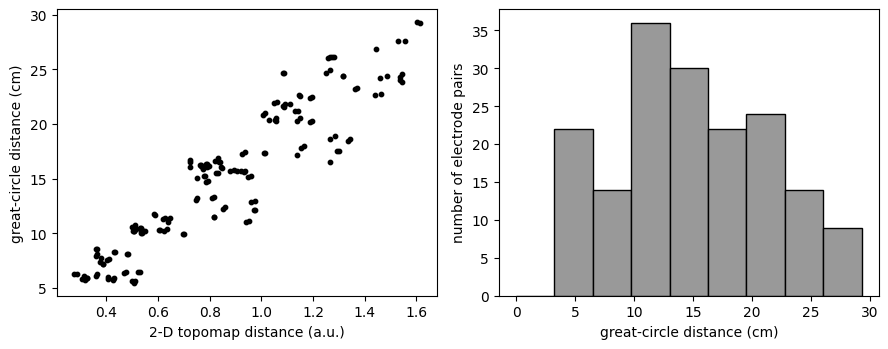

In [7]:
# Lag bins and pair-count diagnostics under each geometry, and how many pairs change bin when the
# 2-D topomap distance is replaced by the great-circle distance.
def lag_bins(D, nbins):
    h = D[IU]; edges = np.linspace(0, h.max() + 1e-9, nbins + 1)
    return edges, np.clip(np.digitize(h, edges) - 1, 0, nbins - 1)

rows = []
for name, D in DISTANCES.items():
    edges, b = lag_bins(D, NBINS_GROUP)
    for k in range(NBINS_GROUP):
        rows.append(dict(geometry=name, bin=k + 1, lower=edges[k], upper=edges[k + 1], n_pairs=int((b == k).sum())))
tab_bins = pd.DataFrame(rows)
save_table(tab_bins.pivot(index="bin", columns="geometry", values="n_pairs").reset_index(), "lag_bin_pair_counts")
_, b_gc = lag_bins(DIST_GC, NBINS_GROUP); _, b_2d = lag_bins(DIST_2D, NBINS_GROUP)
frac_change = float(np.mean(b_gc != b_2d))
print(tab_bins.pivot(index="bin", columns="geometry", values="n_pairs"))
print(f"Pairs that change lag bin (2-D -> great-circle): {100*frac_change:.1f}% of 171")
macro("pctPairsChangeBin", 100 * frac_change, ".0f")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ax[0].scatter(DIST_2D[IU], DIST_GC[IU], s=10, c="k")
ax[0].set_xlabel("2-D topomap distance (a.u.)"); ax[0].set_ylabel("great-circle distance (cm)")
ax[1].hist(DIST_GC[IU], bins=lag_bins(DIST_GC, NBINS_GROUP)[0], color="0.6", edgecolor="k")
ax[1].set_xlabel("great-circle distance (cm)"); ax[1].set_ylabel("number of electrode pairs")
fig.tight_layout(); savefig(fig, "S_geometry_distances"); plt.show()

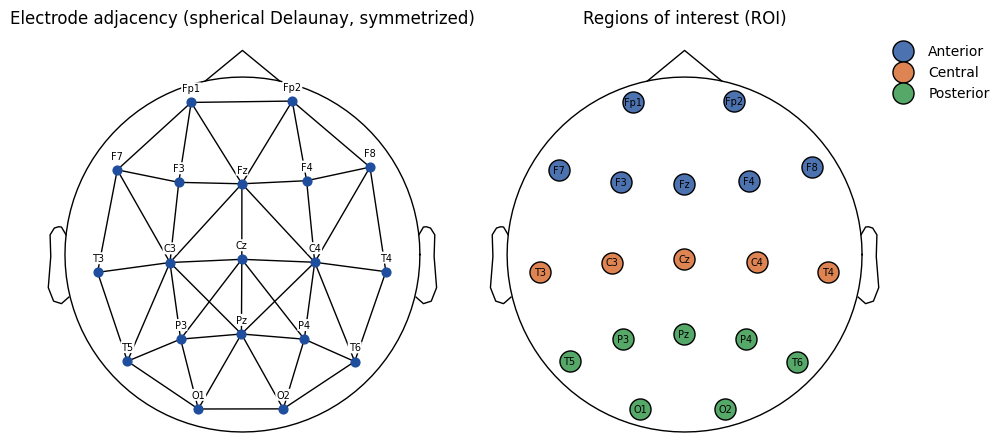

In [8]:
# Figures: adjacency graph (SPHERE_ADJ) and the 3-ROI grouping (SPHERE_ROI).
REGIONS3 = {"Anterior": ['Fp1','Fp2','F7','F3','Fz','F4','F8'],
            "Central": ['T3','C3','Cz','C4','T4'],
            "Posterior": ['T5','P3','Pz','P4','T6','O1','O2']}
REGION3_IDX = {r: [CH_LABELS.index(c) for c in chs] for r, chs in REGIONS3.items()}
REGION_COLORS = {"Anterior": "#4C72B0", "Central": "#DD8452", "Posterior": "#55A868"}

def _sensor_xy(sphere):
    return POS2D

def blank_head(ax, sphere):
    mne.viz.plot_topomap(np.zeros(N_CH), POS2D, axes=ax, show=False, sensors=False, contours=0,
                         cmap=matplotlib.colors.ListedColormap(["white"]), vlim=(0, 1), sphere=sphere)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
blank_head(ax[0], SPHERE_ADJ); xy = _sensor_xy(SPHERE_ADJ)
for i, j in EDGES:
    ax[0].plot(xy[[i, j], 0], xy[[i, j], 1], color="k", lw=1.0, zorder=5)
ax[0].scatter(xy[:, 0], xy[:, 1], s=40, c="#1f4e9e", zorder=6)
for k, c in enumerate(CH_LABELS):
    ax[0].annotate(c, xy[k], xytext=(0, 8), textcoords="offset points", ha="center", fontsize=7,
                   bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none"), zorder=7)
ax[0].set_title("Electrode adjacency (spherical Delaunay, symmetrized)")
blank_head(ax[1], SPHERE_ROI); xy = _sensor_xy(SPHERE_ROI)
for r, idx in REGION3_IDX.items():
    ax[1].scatter(xy[idx, 0], xy[idx, 1], s=230, c=REGION_COLORS[r], edgecolor="k", label=r, zorder=6)
for k, c in enumerate(CH_LABELS):
    ax[1].text(xy[k, 0], xy[k, 1], c, ha="center", va="center", fontsize=7, zorder=7)
ax[1].legend(loc="upper left", bbox_to_anchor=(0.95, 1.0), frameon=False); ax[1].set_title("Regions of interest (ROI)")
fig.tight_layout(); savefig(fig, "F_adjacency_and_roi"); plt.show()

## 3. Event-file audit (AJJ #11, #13)

In [9]:
# Which labels occur, how many recordings contain photic stimulation, whether montage changes
# occur after the recording starts, and which event closes each eyes-closed block.
def read_events(path, sfreq):
    out = []
    for e in json.load(open(path)):
        if isinstance(e, (list, tuple)) and len(e) >= 2:
            out.append((float(e[0]) / sfreq, str(e[1])))
    return sorted(out, key=lambda x: x[0])

def _norm_label(lab):
    lab = lab.strip().lower()
    lab = re.sub(r"\s*-\s*[\d.]+\s*hz", "", lab)          # "photic on - 3.0 hz" -> "photic on"
    lab = re.sub(r"montage\s*\d+", "montage", lab)
    return lab

def _edf_sfreq(path):
    raw = mne.io.read_raw_edf(path, preload=False, verbose=False)
    return raw.info["sfreq"], raw.times[-1]

def audit_events(event_dir, edf_dir, max_files=None):
    files = sorted(glob.glob(os.path.join(event_dir, "*.json")))[:max_files]
    label_counter, ender_counter = Counter(), Counter()
    rows = []
    for f in tqdm(files, desc="event audit"):
        serial = os.path.splitext(os.path.basename(f))[0]
        edf = os.path.join(edf_dir, f"{serial}.edf")
        if not os.path.exists(edf):
            continue
        sf, dur = _edf_sfreq(edf)
        ev = read_events(f, sf)
        labs = [_norm_label(l) for _, l in ev]
        label_counter.update(set(labs))
        for k, (t, l) in enumerate(ev):
            if any(w in l.lower() for w in EYES_CLOSED_KEYWORDS):
                ender_counter[_norm_label(ev[k + 1][1]) if k + 1 < len(ev) else "<end of recording>"] += 1
        rows.append(dict(serial=serial,
                         has_photic=any("photic" in l for l in labs),
                         montage_change_after_start=any(("montage" in l) and (t > 1.0) for (t, _), l in zip(ev, labs)),
                         n_events=len(ev)))
    return pd.DataFrame(rows), label_counter, ender_counter

EVENT_AUDIT, LABELS_SEEN, EC_ENDERS = audit_events(EVENT_DIR, EDF_DIR)
n_files = len(EVENT_AUDIT)
print(f"{n_files} recordings audited")
print("Recordings containing photic stimulation:", int(EVENT_AUDIT.has_photic.sum()))
print("Recordings with a montage change after t > 1 s:", int(EVENT_AUDIT.montage_change_after_start.sum()))
print("\nMost frequent (normalized) labels [number of recordings]:")
for l, c in LABELS_SEEN.most_common(25): print(f"  {c:5d}  {l}")
print("\nEvent that closes an eyes-closed block [number of blocks]:")
for l, c in EC_ENDERS.most_common(15): print(f"  {c:5d}  {l}")
_lab = pd.DataFrame(LABELS_SEEN.most_common(40), columns=["label", "n_recordings"])
_lab["label"] = [l if all(ord(ch) < 0x250 for ch in l) else "[non-Latin label]" for l in _lab.label]
save_table(_lab, "S_event_labels")
_cl = pd.DataFrame(EC_ENDERS.most_common(25), columns=["closing_event", "n_blocks"])
_cl["closing_event"] = [l if all(ord(ch) < 0x250 for ch in l) else "[non-Latin label]" for l in _cl.closing_event]
save_table(_cl, "S_event_ec_closers")
macro("nPhotic", int(EVENT_AUDIT.has_photic.sum())); macro("nMontageChange", int(EVENT_AUDIT.montage_change_after_start.sum()))
macro("nRecordingsAudited", n_files)

event audit:   0%|          | 0/1379 [00:00<?, ?it/s]

1379 recordings audited
Recordings containing photic stimulation: 1055
Recordings with a montage change after t > 1 s: 22

Most frequent (normalized) labels [number of recordings]:
   1379  start recording
   1378  paused
   1377  eyes open
   1370  eyes closed
   1232  new montage - montage
   1055  photic off
   1055  photic on
    455  move
    342  recording resumed
    162  new montage - pz montage
    150  artifact
     97  hv - off
     73  hv fair
     69  swallowing
     31  talk
     29  cough
     29  a2 recheck
     27  a1 recheck
     25  sleep try
     20  chewing
     16  f8 recheck
     15  t4 recheck
     15  f4 recheck
     14  t3 check
     13  fp1 recheck

Event that closes an eyes-closed block [number of blocks]:
   9624  eyes open
   3328  photic on
   1820  photic off
   1195  paused
    348  move
     91  eyes closed
     66  artifact
     46  hv - off
     40  swallowing
     13  a2 recheck
     11  chewing
     11  a1 recheck
     10  sleep try
      9  cough


'1379'

## 4. Preprocessing and spectral estimation (AJJ #26-36)

In [10]:
def ec_intervals(events, total_dur):
    out = []
    for k, (t, lab) in enumerate(events):
        if any(w in lab.lower() for w in EYES_CLOSED_KEYWORDS) and t < total_dur:   # v23.1: skip markers after the EDF end
            end = min(events[k + 1][0] if k + 1 < len(events) else total_dur, total_dur)
            if end > t:
                out.append((t, end))
    return out

def eo_intervals(events, total_dur):
    out = []
    for k, (t, lab) in enumerate(events):
        if any(w in lab.lower() for w in EYES_OPEN_KEYWORDS) and t < total_dur:   # v23.1: skip markers after the EDF end
            end = min(events[k + 1][0] if k + 1 < len(events) else total_dur, total_dur)
            if end > t:
                out.append((t, end))
    return out

def scorepochs(epochs_data, sfreq, fmin=FMIN, fmax=FMAX, nperseg_sec=SCOREPOCHS_NPERSEG_SEC):
    """scorEpochs (Fraschini et al., 2022, Sensors 22:2853): per channel, Welch PSD of every epoch,
    Spearman correlation between the PSDs of all epoch pairs, row-average -> per-epoch score; the
    scores are then averaged across channels. Higher score = epoch more representative of the
    subject's own spectral profile. epochs_data: [n_epochs, n_ch, n_times]."""
    f, P = welch(epochs_data, fs=sfreq, nperseg=int(nperseg_sec * sfreq), axis=-1)
    m = (f >= fmin) & (f <= fmax)
    P = P[..., m]                                       # [n_ep, n_ch, n_f]
    n_ep, n_ch, _ = P.shape
    R = np.argsort(np.argsort(P, axis=-1), axis=-1).astype(float)   # ranks along frequency
    R -= R.mean(-1, keepdims=True); R /= np.linalg.norm(R, axis=-1, keepdims=True)
    score = np.zeros(n_ep)
    for c in range(n_ch):
        rho = R[:, c] @ R[:, c].T                       # Spearman = Pearson on ranks
        score += (rho.sum(1) - 1.0) / (n_ep - 1)
    return score / n_ch

def psd_from_epochs(ep, sfreq, bandwidth):
    psds, freqs = psd_array_multitaper(ep, sfreq=sfreq, fmin=FMIN, fmax=FMAX, bandwidth=bandwidth,
                                       adaptive=PSD_ADAPTIVE, low_bias=PSD_LOW_BIAS,
                                       normalization=PSD_NORMALIZATION, remove_dc=True,
                                       output="power", verbose=False)
    return np.log10(np.clip(np.median(psds, axis=0), 1e-30, None)), freqs   # [n_ch, n_f], log10 V^2/Hz

def process_subject(row, verbose=False):
    """EC extraction (raw signal) -> >= 60 s check -> band-pass + average reference -> 4-s epochs ->
    global autoreject threshold -> ICA (Picard) fitted on the retained epochs of a 1-99 Hz copy ->
    MNE-ICALabel, keep 'brain' -> apply ICA -> resample 128 Hz -> autoreject (local) -> >= 15 clean
    epochs check -> scorEpochs selects 15 epochs -> multitaper PSD (1 Hz; 2 Hz sensitivity) -> median
    across epochs -> log10."""
    import autoreject
    from mne_icalabel import label_components
    serial, lab = row["serial"], row["label"]
    base = dict(serial=serial, label=lab, split=row.get("split"), age=row.get("age"))
    edf = os.path.join(EDF_DIR, f"{serial}.edf"); evf = os.path.join(EVENT_DIR, f"{serial}.json")
    if not (os.path.exists(edf) and os.path.exists(evf)):
        return {**base, "status": "missing EDF/event file"}
    try:
        raw = mne.io.read_raw_edf(edf, preload=True, verbose=False)
        raw.rename_channels({ch: ch.split("-")[0].strip() for ch in raw.ch_names})
        avail = {ch.upper(): ch for ch in raw.ch_names}
        if not all(c.upper() in avail for c in CANONICAL):
            return {**base, "status": "missing EEG channels"}
        raw.pick([avail[c.upper()] for c in CANONICAL])
        raw.rename_channels(dict(zip(raw.ch_names, CH_LABELS)))
        raw.set_channel_types({c: "eeg" for c in CH_LABELS})
        raw.set_montage(template_montage(), match_case=False, on_missing="raise")
        sf, dur = raw.info["sfreq"], raw.times[-1]
        ev = read_events(evf, sf)
        ec, eo = ec_intervals(ev, dur), eo_intervals(ev, dur)
        base.update(ec_sec_raw=sum(b - a for a, b in ec), eo_sec_raw=sum(b - a for a, b in eo), n_ec_blocks=len(ec))
        if base["ec_sec_raw"] < MIN_EC_SEC:
            return {**base, "status": "EC < 60 s (raw)"}

        segs = [raw.copy().crop(a, b, include_tmax=False) for a, b in ec]
        raw_ec = mne.concatenate_raws(segs, verbose=False)          # boundaries annotated as BAD
        raw_ica = raw_ec.copy().filter(1.0, min(ICA_FIT_HIGH_FREQ, sf / 2 - 1), verbose=False)
        raw_ica.set_eeg_reference("average", verbose=False)
        raw_ana = raw_ec.copy().filter(FILTER_L_FREQ, FILTER_H_FREQ, verbose=False)
        raw_ana.set_eeg_reference("average", verbose=False)

        ep_ica = mne.make_fixed_length_epochs(raw_ica, duration=WIN_SEC, reject_by_annotation=True,
                                              preload=True, verbose=False)
        base["n_epochs_raw"] = len(ep_ica)
        if len(ep_ica) < N_EPOCHS_EQUAL:
            return {**base, "status": "fewer than 15 epochs (raw)"}
        rej = autoreject.get_rejection_threshold(ep_ica, random_state=AR_RANDOM_STATE, verbose=False)
        ep_fit = ep_ica.copy().drop_bad(reject=rej, verbose=False)
        if len(ep_fit) < 10:
            ep_fit = ep_ica
        ica = mne.preprocessing.ICA(n_components=N_CH - 1, method=ICA_METHOD, fit_params=ICA_FIT_PARAMS,
                                    random_state=ICA_RANDOM_STATE, max_iter="auto", verbose=False)
        ica.fit(ep_fit, verbose=False)
        labels = label_components(ep_fit, ica, method="iclabel")["labels"]
        ica.exclude = [k for k, l in enumerate(labels) if l not in ICLABEL_KEEP]
        base.update(ic_labels=labels, n_ic_removed=len(ica.exclude))

        raw_ana = ica.apply(raw_ana, verbose=False)
        raw_ana.resample(TARGET_SFREQ, verbose=False)
        ep = mne.make_fixed_length_epochs(raw_ana, duration=WIN_SEC, reject_by_annotation=True,
                                          preload=True, verbose=False)
        ar = autoreject.AutoReject(n_interpolate=AR_N_INTERPOLATE, consensus=AR_CONSENSUS, cv=AR_CV,
                                   random_state=AR_RANDOM_STATE, n_jobs=1, verbose=False)
        ep_clean, log = ar.fit_transform(ep, return_log=True)
        base.update(n_epochs_clean=len(ep_clean), n_epochs_dropped_ar=int(log.bad_epochs.sum()),
                    pct_cells_interpolated=float(100 * (log.labels == 2).mean()))
        if len(ep_clean) < N_EPOCHS_EQUAL:
            return {**base, "status": "fewer than 15 clean epochs (post-preprocessing)"}

        X = ep_clean.get_data()                                   # [n, 19, 512] volts
        score = scorepochs(X, TARGET_SFREQ)
        sel = np.sort(np.argsort(score)[::-1][:N_EPOCHS_EQUAL])
        psd1, freqs = psd_from_epochs(X[sel], TARGET_SFREQ, PSD_BANDWIDTH)
        psd2, _ = psd_from_epochs(X[sel], TARGET_SFREQ, PSD_BANDWIDTH_SENS)
        psd_all, _ = psd_from_epochs(X, TARGET_SFREQ, PSD_BANDWIDTH)
        return {**base, "status": "included", "freqs": freqs, "psd": psd1, "psd_bw2": psd2,
                "psd_all_epochs": psd_all, "score_selected_mean": float(score[sel].mean()),
                "score_all_mean": float(score.mean())}
    except Exception as e:
        return {**base, "status": f"error: {repr(e)[:150]}"}

def load_annotations(path):
    ann = json.load(open(path)); name2lab = ann.get("class_name_to_label")
    rows = []
    for k, v in ann.items():
        if isinstance(v, list) and v and isinstance(v[0], dict):
            split = "train" if "train" in k.lower() else "val" if "val" in k.lower() else "test" if "test" in k.lower() else k
            for e in v:
                lab = e.get("class_label", None)
                if lab is None and name2lab: lab = name2lab.get(e.get("class_name"))
                if lab is not None:
                    rows.append(dict(serial=str(e["serial"]), label=int(lab), split=split, age=e.get("age")))
    return rows

def _cached(row):
    p = os.path.join(SUBJ_CACHE_DIR, f"{row['serial']}.pkl")
    if os.path.exists(p):
        return pickle.load(open(p, "rb"))
    r = process_subject(row)
    if not r["status"].startswith("error"):
        pickle.dump(r, open(p, "wb"))
    return r

ROWS = load_annotations(DEMENTIA_JSON)[:N_SUBJECTS_MAX]
RESULTS = Parallel(n_jobs=N_JOBS, verbose=0)(delayed(_cached)(r) for r in tqdm(ROWS, desc="subjects"))
META = pd.DataFrame([{k: v for k, v in r.items() if k not in ("psd", "psd_bw2", "psd_all_epochs", "freqs", "ic_labels")}
                     for r in RESULTS])
META["group"] = META["label"].map(GROUP_NAMES)
print(META["status"].value_counts())
assert (META.status == "included").sum() > 0, "no subject included -- check paths"

subjects:   0%|          | 0/1122 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


status
included                                           974
EC < 60 s (raw)                                    114
fewer than 15 epochs (raw)                          22
fewer than 15 clean epochs (post-preprocessing)     12
Name: count, dtype: int64


In [11]:
INC = [r for r in RESULTS if r["status"] == "included" and r["label"] in (0, 1, 2)]
FREQS = INC[0]["freqs"]; GRID = np.asarray(FREQS); T = len(GRID)
SUBJECTS = {g: [r["psd"] for r in INC if r["label"] == g] for g in (0, 1, 2)}
SUBJECTS_BW2 = {g: [r["psd_bw2"] for r in INC if r["label"] == g] for g in (0, 1, 2)}
SUBJECTS_ALLEP = {g: [r["psd_all_epochs"] for r in INC if r["label"] == g] for g in (0, 1, 2)}
AGES = {g: np.array([float(r["age"]) if r["age"] is not None else np.nan for r in INC if r["label"] == g]) for g in (0, 1, 2)}
SERIALS = {g: [r["serial"] for r in INC if r["label"] == g] for g in (0, 1, 2)}
IC_REMOVED = {g: np.array([r["n_ic_removed"] for r in INC if r["label"] == g]) for g in (0, 1, 2)}
for g in (0, 1, 2):
    print(f"{GROUP_NAMES[g]:9s}: {len(SUBJECTS[g])} included | PSD [19 x {T}] on {GRID[0]:.2f}-{GRID[-1]:.2f} Hz "
          f"(grid step {np.diff(GRID).mean():.2f} Hz)")
macro("freqStep", np.diff(GRID).mean(), ".2f"); macro("nFreq", T)
pickle.dump(dict(META=META, SUBJECTS=SUBJECTS, SUBJECTS_BW2=SUBJECTS_BW2, SUBJECTS_ALLEP=SUBJECTS_ALLEP,
                 AGES=AGES, SERIALS=SERIALS, FREQS=FREQS), open(os.path.join(OUT_DIR, "psd_v23.pkl"), "wb"))

Normal   : 394 included | PSD [19 x 117] on 1.00-30.00 Hz (grid step 0.25 Hz)
MCI      : 328 included | PSD [19 x 117] on 1.00-30.00 Hz (grid step 0.25 Hz)
Dementia : 252 included | PSD [19 x 117] on 1.00-30.00 Hz (grid step 0.25 Hz)


## 5. Sample characteristics (AJJ #63, #83)

In [12]:
def epsilon_sq(H, n, k=3):
    """Effect size for Kruskal-Wallis (Tomczak & Tomczak, 2014): (H - k + 1) / (n - k)."""
    return (H - k + 1) / (n - k)

def cliffs_delta(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    U = mannwhitneyu(a, b, alternative="two-sided")[0]
    return 2 * U / (len(a) * len(b)) - 1          # P(a > b) - P(a < b)

def cohens_d(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp

def bh_fdr(p):
    p = np.asarray(p, float); n = len(p); o = np.argsort(p)
    q = np.minimum.accumulate((p[o] * n / np.arange(1, n + 1))[::-1])[::-1]
    out = np.empty(n); out[o] = np.clip(q, 0, 1); return out

PAIRS = [(0, 1), (1, 2), (0, 2)]
def compare_groups(vals):
    """vals: dict g -> 1-D array. KW + epsilon^2, Spearman trend with severity (0/1/2), pairwise MW
    (BH-FDR) + Cliff's delta, Normal vs Abnormal MW + Cliff's delta."""
    v = {g: np.asarray(vals[g], float)[np.isfinite(vals[g])] for g in (0, 1, 2)}
    if min(len(x) for x in v.values()) < 3:      # e.g. h95 never identifiable in one group
        nan = float("nan")
        return dict(H=nan, p=nan, eps2=nan, rho=nan, p_rho=nan,
                    med=[float(np.median(v[g])) if len(v[g]) else nan for g in (0, 1, 2)], iqr=None,
                    q_01=nan, q_12=nan, q_02=nan, delta_01=nan, delta_12=nan, delta_02=nan, p_NA=nan, delta_NA=nan)
    H, p = kruskal(v[0], v[1], v[2]); n = sum(len(x) for x in v.values())
    sev = np.concatenate([np.full(len(v[g]), g) for g in (0, 1, 2)])
    rho, prho = spearmanr(sev, np.concatenate([v[g] for g in (0, 1, 2)]))
    pw = [mannwhitneyu(v[a], v[b], alternative="two-sided")[1] for a, b in PAIRS]
    out = dict(H=H, p=p, eps2=epsilon_sq(H, n), rho=rho, p_rho=prho,
               med=[float(np.median(v[g])) for g in (0, 1, 2)],
               iqr=[tuple(np.percentile(v[g], [25, 75])) for g in (0, 1, 2)])
    for (a, b), pp, qq in zip(PAIRS, pw, bh_fdr(pw)):
        out[f"q_{a}{b}"] = qq; out[f"delta_{a}{b}"] = cliffs_delta(v[b], v[a])     # >0: later group higher
    ab = np.concatenate([v[1], v[2]])
    out["p_NA"] = mannwhitneyu(v[0], ab, alternative="two-sided")[1]; out["delta_NA"] = cliffs_delta(ab, v[0])
    return out

# --- inclusion flow ---
flow = META.groupby(["status", "group"]).size().unstack(fill_value=0)
flow["total"] = flow.sum(1)
save_table(flow.reset_index(), "S_inclusion_flow", float_format="%.0f"); print(flow)
n_inc = {g: len(SUBJECTS[g]) for g in (0, 1, 2)}
for g, nm in GROUP_NAMES.items():
    macro(f"n{nm}", n_inc[g])
    macro(f"nAnnot{nm}", int((META.label == g).sum()))
macro("nTotal", sum(n_inc.values())); macro("nAbnormal", n_inc[1] + n_inc[2])
macro("nAnnotTotal", len(META)); macro("nExcluded", len(META) - sum(n_inc.values()))
macro("nExclShortRaw", int((META.status == "EC < 60 s (raw)").sum()))
macro("nExclShortClean", int(META.status.str.startswith("fewer than 15").sum()))

# --- age and recording characteristics ---
inc_meta = META[META.status == "included"].copy()
rows = []
for g in (0, 1, 2):
    d = inc_meta[inc_meta.label == g]
    rows.append(dict(Group=GROUP_NAMES[g], n=len(d),
                     **{"Age, mean (SD)": f"{d.age.mean():.1f} ({d.age.std():.1f})",
                        "Age, median [IQR]": f"{d.age.median():.0f} [{d.age.quantile(.25):.0f}-{d.age.quantile(.75):.0f}]",
                        "EC (min), median [range]": f"{d.ec_sec_raw.median()/60:.2f} [{d.ec_sec_raw.min()/60:.2f}-{d.ec_sec_raw.max()/60:.2f}]",
                        "EO (min), median [range]": f"{d.eo_sec_raw.median()/60:.2f} [{d.eo_sec_raw.min()/60:.2f}-{d.eo_sec_raw.max()/60:.2f}]",
                        "Clean epochs, median [range]": f"{d.n_epochs_clean.median():.0f} [{d.n_epochs_clean.min():.0f}-{d.n_epochs_clean.max():.0f}]",
                        "ICs removed, median [range]": f"{d.n_ic_removed.median():.0f} [{d.n_ic_removed.min():.0f}-{d.n_ic_removed.max():.0f}]"}))
    macro(f"ageMean{GROUP_NAMES[g]}", d.age.mean(), ".1f"); macro(f"ageSd{GROUP_NAMES[g]}", d.age.std(), ".1f")
    macro(f"ecMedian{GROUP_NAMES[g]}", d.ec_sec_raw.median() / 60, ".2f")
TAB_SAMPLE = save_table(pd.DataFrame(rows), "T1_sample_characteristics")
print(TAB_SAMPLE.to_string(index=False))

age_cmp = compare_groups(AGES)
d_nd = cohens_d(AGES[2][np.isfinite(AGES[2])], AGES[0][np.isfinite(AGES[0])])
print(f"Age: KW H={age_cmp['H']:.2f}, p={age_cmp['p']:.2e}, epsilon^2={age_cmp['eps2']:.3f}; "
      f"Cohen's d (Dementia - Normal) = {d_nd:.2f}")
macro("ageH", age_cmp["H"], ".1f"); macro("ageP", fmt_p(age_cmp["p"])); macro("ageEps", age_cmp["eps2"], ".2f")
macro("ageDND", d_nd, ".2f")
ec_cmp = compare_groups({g: inc_meta[inc_meta.label == g].ec_sec_raw.values / 60 for g in (0, 1, 2)})
macro("ecH", ec_cmp["H"], ".1f"); macro("ecP", fmt_p(ec_cmp["p"])); macro("ecEps", ec_cmp["eps2"], ".3f")
ic_cmp = compare_groups({g: IC_REMOVED[g] for g in (0, 1, 2)})
macro("icP", fmt_p(ic_cmp["p"])); macro("icEps", ic_cmp["eps2"], ".3f")
macro("pctInterp", inc_meta.pct_cells_interpolated.median(), ".1f")

group                                            Dementia  MCI  Normal  total
status                                                                       
EC < 60 s (raw)                                        30   51      33    114
fewer than 15 clean epochs (post-preprocessing)         1    7       4     12
fewer than 15 epochs (raw)                              8    9       5     22
included                                              252  328     394    974
   Group   n Age, mean (SD) Age, median [IQR] EC (min), median [range] EO (min), median [range] Clean epochs, median [range] ICs removed, median [range]
  Normal 394     64.7 (9.5)        64 [58-72]        6.01 [1.30-11.59]         3.74 [0.07-6.74]                  76 [16-165]                    5 [1-13]
     MCI 328     73.5 (7.9)        74 [69-79]        6.43 [1.53-14.48]         3.65 [0.53-6.90]                  80 [15-199]                    5 [0-12]
Dementia 252     76.4 (8.1)        78 [72-82]        6.74 [1.15-12.66]   

'7.3'

## 6. Functional representation (penalized B-splines, GCV)

In [13]:
def design_matrix(basis, t):
    M = np.asarray(basis(t)); return M.reshape(M.shape[0], -1).T

def penalty_matrix(basis, order=PENALTY_ORDER):
    return np.asarray(gram_matrix(LinearDifferentialOperator(order), basis))

def gcv_curve(lam, Phi, Y, Pm):
    n = Phi.shape[0]; A = Phi.T @ Phi + lam * Pm
    S = Phi @ np.linalg.solve(A, Phi.T); edf = np.trace(S)
    Yhat = (S @ Y.T).T
    gcv = n * np.sum((Y - Yhat) ** 2, axis=1) / (n - edf) ** 2
    return float(gcv.mean()), float(edf)

rng = np.random.default_rng(SEED)
_sample = np.concatenate([np.stack(SUBJECTS[g][:20]).reshape(-1, T) for g in (0, 1, 2)])
_sample = _sample[rng.choice(len(_sample), size=min(300, len(_sample)), replace=False)]
CANDIDATES = {"B-spline": BSplineBasis(domain_range=(GRID[0], GRID[-1]), n_basis=N_BASIS_RICH, order=BSPLINE_ORDER),
              "Fourier": FourierBasis(domain_range=(GRID[0], GRID[-1]), n_basis=N_BASIS_RICH + 1)}
GCV_RES = {}
for name, basis in CANDIDATES.items():
    Phi, Pm = design_matrix(basis, GRID), penalty_matrix(basis)
    sc = [(lam,) + gcv_curve(lam, Phi, _sample, Pm) for lam in LAMBDA_GRID]
    lam, gcv, edf = min(sc, key=lambda s: s[1])
    GCV_RES[name] = dict(basis=basis, Phi=Phi, Pm=Pm, lam=lam, gcv=gcv, edf=edf, scores=sc)
    print(f"{name:8s}: lambda*={lam:.2e}  GCV={gcv:.4f}  edf={edf:.1f}/{basis.n_basis}")
BASIS_TYPE = min(GCV_RES, key=lambda k: GCV_RES[k]["gcv"])
BASIS, LAMBDA_STAR = GCV_RES[BASIS_TYPE]["basis"], GCV_RES[BASIS_TYPE]["lam"]
PHI, PEN = GCV_RES[BASIS_TYPE]["Phi"], GCV_RES[BASIS_TYPE]["Pm"]
W = np.asarray(BASIS.gram_matrix())
_SMOOTHER = np.linalg.solve(PHI.T @ PHI + LAMBDA_STAR * PEN, PHI.T)        # [n_basis, n_freq]
def fit_penalized(Y): return (_SMOOTHER @ np.asarray(Y).T).T
_m, _e = f"{LAMBDA_STAR:.2e}".split("e"); macro("lambdaStar", f"\\ensuremath{{{_m}\\times 10^{{{int(_e)}}}}}")
macro("edf", GCV_RES[BASIS_TYPE]["edf"], ".1f"); macro("gcvBspline", GCV_RES["B-spline"]["gcv"], ".4f")
macro("gcvFourier", GCV_RES["Fourier"]["gcv"], ".4f"); macro("basisSelected", BASIS_TYPE)

COEFS = {g: [fit_penalized(s) for s in SUBJECTS[g]] for g in (0, 1, 2)}
COEFS_BW2 = {g: [fit_penalized(s) for s in SUBJECTS_BW2[g]] for g in (0, 1, 2)}
COEFS_ALLEP = {g: [fit_penalized(s) for s in SUBJECTS_ALLEP[g]] for g in (0, 1, 2)}

B-spline: lambda*=1.58e-02  GCV=0.0058  edf=33.1/40
Fourier : lambda*=6.31e-02  GCV=0.0450  edf=26.9/41


## 7. Functional age residualization

In [14]:
# Unchanged method (v17): per channel, OLS of the B-spline coefficients on a cubic age spline,
# diagnosis indicators and age x diagnosis interactions; each subject is projected to the sample
# mean age with the SAME diagnosis, so only within-group age variation is removed (AJJ #58-59).
ALL_AGES = np.concatenate([AGES[g] for g in (0, 1, 2)])
REFERENCE_AGE = float(np.nanmean(ALL_AGES)); macro("refAge", REFERENCE_AGE, ".1f")

def residualize_by_age(coefs, ages, n_knots=6, degree=3):
    groups = np.concatenate([np.full(len(coefs[g]), g) for g in (0, 1, 2)])
    a = np.concatenate([ages[g] for g in (0, 1, 2)]); ok = np.isfinite(a)
    st = SplineTransformer(n_knots=n_knots, degree=degree, include_bias=False).fit((a[ok] - REFERENCE_AGE)[:, None])
    def design(age_vals, grp):
        S = st.transform((age_vals - REFERENCE_AGE)[:, None])
        Dg = np.column_stack([(grp == 1), (grp == 2)]).astype(float)
        return np.column_stack([np.ones(len(grp)), S, Dg, S * Dg[:, [0]], S * Dg[:, [1]]])
    X, Xr = design(a[ok], groups[ok]), design(np.full(ok.sum(), REFERENCE_AGE), groups[ok])
    flat = [c.copy() for g in (0, 1, 2) for c in coefs[g]]
    idx_ok = np.where(ok)[0]
    for ch in range(N_CH):
        Y = np.stack([flat[i][ch] for i in idx_ok])
        beta = np.linalg.lstsq(X, Y, rcond=None)[0]
        Yadj = Y - (X @ beta - Xr @ beta)
        for i, y in zip(idx_ok, Yadj): flat[i][ch] = y
    out, k = {}, 0
    for g in (0, 1, 2):
        out[g] = flat[k:k + len(coefs[g])]; k += len(coefs[g])
    return out

COEFS_AGE = residualize_by_age(COEFS, AGES)

# Common age support (sensitivity): ages inside [max_g P5, min_g P95] of the three groups.
AGE_LO = max(np.nanpercentile(AGES[g], 5) for g in (0, 1, 2))
AGE_HI = min(np.nanpercentile(AGES[g], 95) for g in (0, 1, 2))
IN_SUPPORT = {g: (AGES[g] >= AGE_LO) & (AGES[g] <= AGE_HI) for g in (0, 1, 2)}
macro("ageSupportLo", AGE_LO, ".0f"); macro("ageSupportHi", AGE_HI, ".0f")
for g in (0, 1, 2): macro(f"nSupport{GROUP_NAMES[g]}", int(IN_SUPPORT[g].sum()))
print(f"Common age support: {AGE_LO:.0f}-{AGE_HI:.0f} years | n = {[int(IN_SUPPORT[g].sum()) for g in (0, 1, 2)]}")

Common age support: 61-80 years | n = [247, 248, 153]


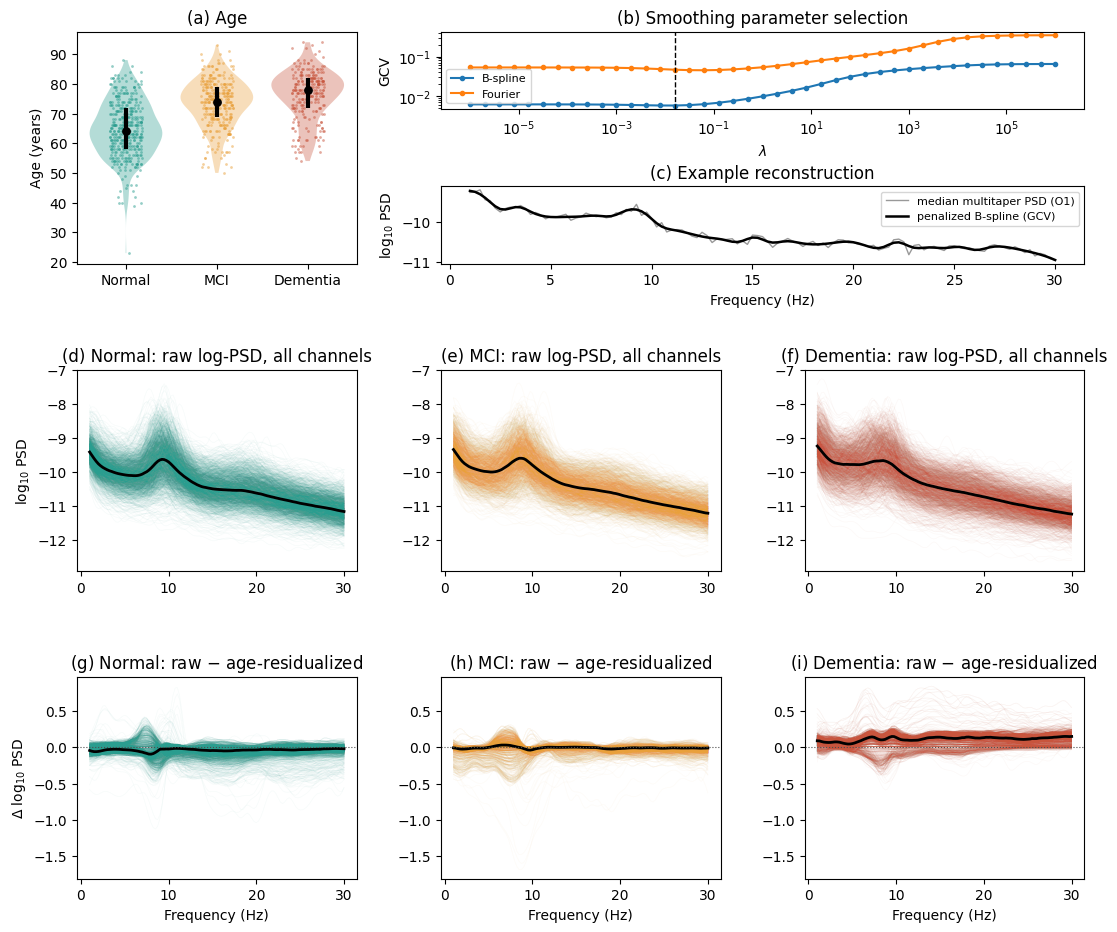

In [15]:
# Combined panel (AJJ #64, #86): row 1 = age distribution by group | GCV curve + example
# reconstruction (stacked); rows 2-3 = all channels' raw log-PSD and the subject-by-channel
# difference (raw - age-residualized), per group, with the group median in black.
def violin_points(ax, vals, ylabel, title=None):
    data = [np.asarray(vals[g], float)[np.isfinite(vals[g])] for g in (0, 1, 2)]
    parts = ax.violinplot(data, positions=[0, 1, 2], showextrema=False, widths=0.8)
    for pc, g in zip(parts["bodies"], (0, 1, 2)):
        pc.set_facecolor(GROUP_COLORS[g]); pc.set_alpha(0.35); pc.set_edgecolor("none")
    jr = np.random.default_rng(1)
    for g, d in zip((0, 1, 2), data):
        ax.scatter(g + jr.uniform(-0.18, 0.18, len(d)), d, s=4, color=GROUP_COLORS[g], alpha=0.5, lw=0)
        q1, med, q3 = np.percentile(d, [25, 50, 75])
        ax.vlines(g, q1, q3, color="k", lw=3); ax.scatter([g], [med], color="k", s=28, zorder=5)
    ax.set_xticks([0, 1, 2]); ax.set_xticklabels([GROUP_NAMES[g] for g in (0, 1, 2)])
    ax.set_ylabel(ylabel)
    if title: ax.set_title(title)

fig = plt.figure(figsize=(13, 11))
gs = GridSpec(3, 3, figure=fig, height_ratios=[1.15, 1.0, 1.0], hspace=0.5, wspace=0.3)
ax_age = fig.add_subplot(gs[0, 0]); violin_points(ax_age, AGES, "Age (years)", "(a) Age")
sub = gs[0, 1:].subgridspec(2, 1, hspace=1.0)
ax_g = fig.add_subplot(sub[0])
for name, r in GCV_RES.items():
    l, s, _ = zip(*r["scores"]); ax_g.plot(l, s, "o-", ms=3, label=name)
ax_g.axvline(LAMBDA_STAR, color="k", ls="--", lw=1); ax_g.set_xscale("log"); ax_g.set_yscale("log")
ax_g.set_xlabel(r"$\lambda$"); ax_g.set_ylabel("GCV"); ax_g.legend(fontsize=8); ax_g.set_title("(b) Smoothing parameter selection")
ax_r = fig.add_subplot(sub[1]); _ex = SUBJECTS[0][0][CH_LABELS.index("O1")]
ax_r.plot(GRID, _ex, color="0.6", lw=1, label="median multitaper PSD (O1)")
ax_r.plot(GRID, PHI @ fit_penalized(_ex[None])[0], color="k", lw=1.8, label="penalized B-spline (GCV)")
ax_r.set_xlabel("Frequency (Hz)"); ax_r.set_ylabel(r"log$_{10}$ PSD"); ax_r.legend(fontsize=8); ax_r.set_title("(c) Example reconstruction")
for col, g in enumerate((0, 1, 2)):
    raw_c = np.stack([PHI @ Z.T for Z in COEFS[g]])          # [n, f, 19]
    adj_c = np.stack([PHI @ Z.T for Z in COEFS_AGE[g]])
    ax1 = fig.add_subplot(gs[1, col], sharey=None if col == 0 else _ax1_0)
    ax2 = fig.add_subplot(gs[2, col], sharey=None if col == 0 else _ax2_0)
    if col == 0: _ax1_0, _ax2_0 = ax1, ax2
    flat_raw = raw_c.transpose(0, 2, 1).reshape(-1, T); flat_dif = (raw_c - adj_c).transpose(0, 2, 1).reshape(-1, T)
    step = max(1, len(flat_raw) // 1500)
    ax1.plot(GRID, flat_raw[::step].T, color=GROUP_COLORS[g], alpha=0.04, lw=0.5)
    ax1.plot(GRID, np.median(flat_raw, 0), "k", lw=2); ax1.set_title(f"({'def'[col]}) {GROUP_NAMES[g]}: raw log-PSD, all channels")
    ax2.plot(GRID, flat_dif[::step].T, color=GROUP_COLORS[g], alpha=0.04, lw=0.5)
    ax2.plot(GRID, np.median(flat_dif, 0), "k", lw=2); ax2.axhline(0, color="0.3", lw=0.8, ls=":")
    ax2.set_title(f"({'ghi'[col]}) {GROUP_NAMES[g]}: raw $-$ age-residualized"); ax2.set_xlabel("Frequency (Hz)")
    if col == 0: ax1.set_ylabel(r"log$_{10}$ PSD"); ax2.set_ylabel(r"$\Delta$ log$_{10}$ PSD")
savefig(fig, "F1_sample_and_functional_representation"); plt.show()

## 8. Functional dissimilarity metrics (with audits of the Wasserstein / Fisher-Rao inputs)

In [16]:
# Every analysis below works from per-subject matrices of SQUARED dissimilarities D2[j, k]
# between the 19 electrodes; the variogram applies the factor 1/2 exactly once (no double squaring).
TRAPZ_W = np.zeros(T); TRAPZ_W[:-1] += np.diff(GRID) / 2; TRAPZ_W[1:] += np.diff(GRID) / 2
N_QUANTILE = 200; QLEVELS = (np.arange(N_QUANTILE) + 0.5) / N_QUANTILE

def density_from_coefs(Z):
    """log10-PSD (smoothed) -> linear PSD -> density on [FMIN, FMAX] integrating to 1. [19, n_f]"""
    lin = np.power(10.0, PHI @ Z.T).T                                    # back-transform (positive)
    lin = np.maximum(lin, np.finfo(float).tiny)
    dens = lin / (lin @ TRAPZ_W)[:, None]
    assert np.all(dens > 0) and np.allclose(dens @ TRAPZ_W, 1.0, atol=1e-8)
    return dens

def d2_l2(Z, Wm):
    Q = np.einsum("ik,kl,il->i", Z, Wm, Z); C = Z @ Wm @ Z.T
    D = np.clip(Q[:, None] + Q[None] - 2 * C, 0, None); np.fill_diagonal(D, 0); return D

def d2_wasserstein(Z):
    dens = density_from_coefs(Z)
    cdf = np.stack([cumulative_trapezoid(p, GRID, initial=0.0) for p in dens]); cdf[:, -1] = 1.0
    Qf = np.stack([np.interp(QLEVELS, c, GRID) for c in cdf])           # quantile functions (Hz)
    D = ((Qf[:, None] - Qf[None]) ** 2).mean(-1); np.fill_diagonal(D, 0); return D     # W2^2 (Hz^2)

def d2_fisher_rao(Z):
    psi = np.sqrt(density_from_coefs(Z)) * np.sqrt(TRAPZ_W)             # unit vectors
    assert np.allclose((psi ** 2).sum(1), 1.0, atol=1e-8)
    D = np.arccos(np.clip(psi @ psi.T, -1, 1)) ** 2; np.fill_diagonal(D, 0); return D  # rad^2

_allvec = np.vstack([Z for g in (0, 1, 2) for Z in COEFS[g]])
_S = np.cov(_allvec, rowvar=False); _S = 0.999 * _S + 0.001 * np.trace(_S) / len(_S) * np.eye(len(_S))
W_MAHA = np.linalg.inv(_S)

METRICS = {"L2": lambda Z: d2_l2(Z, W), "Wasserstein": d2_wasserstein,
           "Mahalanobis": lambda Z: d2_l2(Z, W_MAHA), "Fisher-Rao": d2_fisher_rao}
METRIC_UNITS = {"L2": r"(log$_{10}$ PSD)$^2$", "Wasserstein": r"Hz$^2$", "Mahalanobis": "a.u.", "Fisher-Rao": r"rad$^2$"}

def d2_stack(coefs, metric):
    return {g: np.stack([METRICS[metric](Z) for Z in coefs[g]]) for g in (0, 1, 2)}

VARIANTS = {"raw": COEFS, "age-adjusted": COEFS_AGE}
D2 = {(m, v): d2_stack(C, m) for m in METRICS for v, C in VARIANTS.items()}
D2_SENS = {"PSD bandwidth 2 Hz": d2_stack(COEFS_BW2, "L2"), "all clean epochs": d2_stack(COEFS_ALLEP, "L2")}
_cnt = sum(len(COEFS[g]) for g in (0, 1, 2))
print(f"Dissimilarity matrices computed: {len(D2)} metric x variant combinations, {_cnt} subjects each")

Dissimilarity matrices computed: 8 metric x variant combinations, 974 subjects each


## 9. Empirical trace-variogram (great-circle lags) and variogram models

In [17]:
def variogram(D2s, D=DIST_GC, nbins=NBINS_GROUP):
    """D2s: [n_subj, 19, 19] squared dissimilarities -> (lag centres, gamma, pair counts).
    gamma(h) = 1/(2 N(h)) sum d^2 over all subjects' pairs in the bin (Giraldo et al., 2011)."""
    edges, b = lag_bins(D, nbins); cen = 0.5 * (edges[:-1] + edges[1:])
    g = D2s[:, IU[0], IU[1]]                                    # [n, 171]
    num = np.bincount(b, weights=g.sum(0), minlength=nbins); cnt = np.bincount(b, minlength=nbins) * len(D2s)
    m = cnt > 0
    return cen[m], 0.5 * num[m] / cnt[m], cnt[m]

def exponential(h, c0, c1, a): return c0 + c1 * (1 - np.exp(-h / a))
def spherical(h, c0, c1, a):
    r = np.minimum(h / a, 1.0); return c0 + c1 * (1.5 * r - 0.5 * r ** 3)
def gaussian(h, c0, c1, a): return c0 + c1 * (1 - np.exp(-(h / a) ** 2))
def _matern_corr(h, a, nu):
    r = np.sqrt(2 * nu) * np.maximum(np.asarray(h, float), 1e-10) / a
    return np.where(np.asarray(h) <= 1e-10, 1.0, (2 ** (1 - nu) / _gamma_fn(nu)) * r ** nu * _kv(nu, r))
def matern15(h, c0, c1, a): return c0 + c1 * (1 - _matern_corr(h, a, 1.5))
def matern25(h, c0, c1, a): return c0 + c1 * (1 - _matern_corr(h, a, 2.5))
MODELS = {"exponential": exponential, "spherical": spherical, "Gaussian": gaussian,
          "Matérn (ν=1.5)": matern15, "Matérn (ν=2.5)": matern25}

def h95(model, a):
    """Practical range: distance at which the model reaches 95 % of the partial sill. Converts the
    model-specific scale parameter a into a quantity comparable across models."""
    if model == "spherical": return a
    if model == "exponential": return -np.log(0.05) * a
    if model == "Gaussian": return np.sqrt(-np.log(0.05)) * a
    nu = 1.5 if "1.5" in model else 2.5
    return brentq(lambda h: _matern_corr(h, a, nu) - 0.05, 1e-6 * a, 50 * a)

A_MAX_FACTOR = 3.0      # scale parameter allowed up to 3 x the largest observed lag (then flagged)
def fit_variogram(name, cen, gam, cnt, tol=0.01):
    f = MODELS[name]; hmax, gmax = cen.max(), gam.max()
    lo, hi = [0, 0, 1e-3], [gmax, 5 * gmax, A_MAX_FACTOR * hmax]
    sig = 1 / np.sqrt(np.maximum(cnt, 1)); best = None
    for a0 in (0.25 * hmax, 0.5 * hmax, hmax, 2 * hmax):
        p0 = [min(gam.min(), 0.9 * gmax), max(gam.max() - gam.min(), 1e-6), min(a0, 0.99 * hi[2])]
        try:
            popt, _ = curve_fit(f, cen, gam, p0=p0, bounds=(lo, hi), sigma=sig, maxfev=20000)
        except Exception:
            continue
        rss = float(np.sum(((gam - f(cen, *popt)) / sig) ** 2))
        if best is None or rss < best[1]: best = (popt, rss)
    if best is None: return None
    popt, rss = best; n, k = len(cen), 3; pred = f(cen, *popt)
    aicc = n * np.log(rss / n + 1e-300) + 2 * k + (2 * k * (k + 1) / (n - k - 1) if n - k - 1 > 0 else np.nan)
    hr = h95(name, popt[2]); on_bound = bool(popt[2] >= hi[2] * (1 - tol) or popt[1] >= hi[1] * (1 - tol))
    return dict(model=name, nugget=popt[0], psill=popt[1], sill=popt[0] + popt[1], a=popt[2], h95=hr,
                rmse=float(np.sqrt(np.mean((pred - gam) ** 2))),
                r2=float(1 - np.sum((gam - pred) ** 2) / (np.sum((gam - gam.mean()) ** 2) + 1e-12)),
                aicc=aicc, on_bound=on_bound, identifiable=bool((hr <= hmax) and not on_bound))

def akaike_weights(fits):
    a = np.array([f["aicc"] for f in fits]); w = np.exp(-0.5 * (a - np.nanmin(a))); return w / np.nansum(w)

In [18]:
# Group-level fits (primary metric L2, raw): all five models, AICc, h95, identifiability; the
# COMMON model is the one with the lowest AICc summed over the three groups (AJJ #88).
EMP = {}
def group_level_table(metric="L2", variant="raw", D=DIST_GC):
    rows = []
    for g in (0, 1, 2):
        cen, gam, cnt = variogram(D2[(metric, variant)][g], D); EMP[(metric, variant, g)] = (cen, gam, cnt)
        fits = [f for f in (fit_variogram(m, cen, gam, cnt) for m in MODELS) if f is not None]
        for f, w in zip(fits, akaike_weights(fits)):
            rows.append(dict(metric=metric, variant=variant, group=GROUP_NAMES[g], akaike_w=w, hmax=cen.max(), **f))
    return pd.DataFrame(rows)

GL = pd.concat([group_level_table(m, v) for m in METRICS for v in VARIANTS], ignore_index=True)
COMMON_MODEL = (GL[(GL.metric == "L2") & (GL.variant == "raw")].groupby("model").aicc.sum().idxmin())
print("Common variogram model (lowest pooled AICc, L2/raw):", COMMON_MODEL)
macro("commonModel", COMMON_MODEL)
gl_main = GL[(GL.metric == "L2") & (GL.variant == "raw") & (GL.model == COMMON_MODEL)]
print(gl_main[["group", "nugget", "sill", "a", "h95", "hmax", "r2", "on_bound", "identifiable"]].round(3).to_string(index=False))
for _, r in gl_main.iterrows():
    nm = r.group
    macro(f"glSill{nm}", r.sill, ".3f"); macro(f"glNugget{nm}", r.nugget, ".3f")
    macro(f"glHns{nm}", r.h95, ".1f"); macro(f"glRsq{nm}", r.r2, ".3f")
    macro(f"glIdent{nm}", "yes" if r.identifiable else "no")
save_table(GL[(GL.metric == "L2") & (GL.variant == "raw")][["group", "model", "nugget", "sill", "a", "h95", "rmse", "r2", "aicc", "akaike_w", "on_bound", "identifiable"]],
           "S_group_level_all_models")
_cols = ["metric", "variant", "group", "nugget", "sill", "h95", "hmax", "r2", "identifiable"]
save_table(GL[(GL.model == COMMON_MODEL) & (GL.metric == "L2")][_cols[1:]], "T2_group_level_common_model")
save_table(GL[GL.model == COMMON_MODEL][_cols], "S_group_level_all_metrics")

# Bootstrap over subjects (common model, L2 raw): CIs for sill and h95 and the fraction of
# resamples in which h95 is identifiable.
def bootstrap_group(D2s, model, n_boot=N_BOOT, seed=SEED):
    r = np.random.default_rng(seed); n = len(D2s); out = []
    for _ in range(n_boot):
        cen, gam, cnt = variogram(D2s[r.integers(0, n, n)])
        f = fit_variogram(model, cen, gam, cnt)
        if f: out.append((f["sill"], f["h95"], f["identifiable"]))
    return np.array(out, float)
BOOT = {g: bootstrap_group(D2[("L2", "raw")][g], COMMON_MODEL) for g in (0, 1, 2)}
for g in (0, 1, 2):
    b = BOOT[g]; nm = GROUP_NAMES[g]
    lo, hi = np.percentile(b[:, 0], [2.5, 97.5]); macro(f"bootSillLo{nm}", lo, ".3f"); macro(f"bootSillHi{nm}", hi, ".3f")
    macro(f"bootIdent{nm}", 100 * b[:, 2].mean(), ".0f")
    print(f"{nm:9s} sill 95% CI [{lo:.3f}, {hi:.3f}] | h95 identifiable in {100*b[:,2].mean():.0f}% of resamples")
_d = BOOT[0][:, 0] - BOOT[2][:, 0][:len(BOOT[0])]
macro("bootSillDiffLo", np.percentile(_d, 2.5), ".3f"); macro("bootSillDiffHi", np.percentile(_d, 97.5), ".3f")

Common variogram model (lowest pooled AICc, L2/raw): exponential
   group  nugget  sill      a     h95   hmax    r2  on_bound  identifiable
  Normal   0.473 5.326 83.034 248.748 27.678 0.896      True         False
     MCI   0.483 3.351 53.379 159.908 27.678 0.917     False         False
Dementia   0.383 2.027 18.773  56.239 27.678 0.901     False         False
Normal    sill 95% CI [4.900, 5.742] | h95 identifiable in 0% of resamples
MCI       sill 95% CI [2.232, 4.977] | h95 identifiable in 0% of resamples
Dementia  sill 95% CI [1.696, 2.832] | h95 identifiable in 0% of resamples


'3.809'

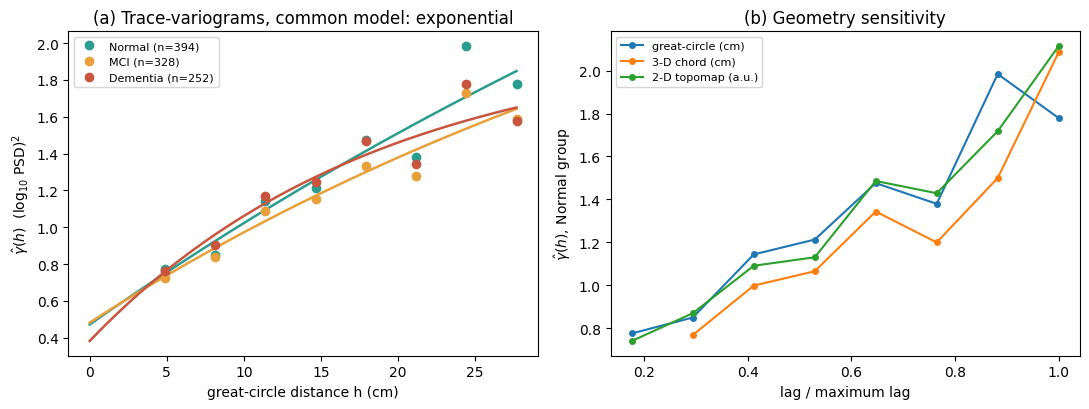

In [19]:
# Figure: empirical variograms of the three groups (L2, raw) with the common model, pair counts.
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for g in (0, 1, 2):
    cen, gam, cnt = EMP[("L2", "raw", g)]
    r = gl_main[gl_main.group == GROUP_NAMES[g]].iloc[0]; hh = np.linspace(0, cen.max(), 200)
    ax[0].plot(cen, gam, "o", color=GROUP_COLORS[g], label=f"{GROUP_NAMES[g]} (n={len(COEFS[g])})")
    ax[0].plot(hh, MODELS[COMMON_MODEL](hh, r.nugget, r.psill, r.a), color=GROUP_COLORS[g], lw=1.8)
ax[0].set_xlabel("great-circle distance h (cm)"); ax[0].set_ylabel(r"$\hat\gamma(h)$  " + METRIC_UNITS["L2"])
ax[0].set_title(f"(a) Trace-variograms, common model: {COMMON_MODEL}"); ax[0].legend(fontsize=8)
for name, D in DISTANCES.items():
    cen, gam, _ = variogram(D2[("L2", "raw")][0], D)
    ax[1].plot(cen / cen.max(), gam, "o-", ms=4, label=name)
ax[1].set_xlabel("lag / maximum lag"); ax[1].set_ylabel(r"$\hat\gamma(h)$, Normal group")
ax[1].set_title("(b) Geometry sensitivity"); ax[1].legend(fontsize=8)
fig.tight_layout(); savefig(fig, "F2_variograms"); plt.show()

## 10. Subject-level endpoints: observed-domain summaries (primary) and common-model parameters

In [20]:
SHORT_MASK = ADJ[IU]                                           # adjacent pairs (frozen graph)
_h = DIST_GC[IU]; LONG_MASK = _h >= np.quantile(_h, 2 / 3)    # upper tertile of distances
macro("nShortPairs", int(SHORT_MASK.sum())); macro("nLongPairs", int(LONG_MASK.sum()))
macro("longLagCm", np.quantile(_h, 2 / 3), ".1f")

def observed_endpoints(D2s, D=DIST_GC, nbins=NBINS_SUBJECT):
    """Per subject: AUC of the empirical variogram over the sampled lags (trapezoid between the
    first and last bin centre, divided by that span -> lag-averaged semivariance, same units as gamma),
    short-lag semivariance (adjacent electrodes), long-lag semivariance (upper distance tertile)
    and the short/long ratio."""
    edges, b = lag_bins(D, nbins); cen = 0.5 * (edges[:-1] + edges[1:])
    G = 0.5 * D2s[:, IU[0], IU[1]]
    gam = np.stack([np.bincount(b, weights=row, minlength=nbins) / np.maximum(np.bincount(b, minlength=nbins), 1) for row in G])
    ok = np.bincount(b, minlength=nbins) > 0
    auc = _trapz(gam[:, ok], cen[ok], axis=1) / (cen[ok][-1] - cen[ok][0])
    hD = D[IU]; long_mask = hD >= np.quantile(hD, 2 / 3)       # upper tertile under the geometry used
    short, long_ = G[:, SHORT_MASK].mean(1), G[:, long_mask].mean(1)
    return dict(AUC=auc, short=short, long=long_, ratio=short / long_, gamma=gam, cen=cen[ok])

def subject_model(D2s, model=COMMON_MODEL, D=DIST_GC, nbins=NBINS_SUBJECT):
    out = []
    for s in range(len(D2s)):
        cen, gam, cnt = variogram(D2s[[s]], D, nbins)
        out.append(fit_variogram(model, cen, gam, cnt) if len(cen) >= 4 else None)
    return out

ENDPOINT_LABELS = {"AUC": "lag-averaged semivariance (AUC)", "short": "short-lag semivariance",
                   "long": "long-lag semivariance", "ratio": "short/long ratio",
                   "sill": f"sill ({COMMON_MODEL})", "h95": f"practical range h95 ({COMMON_MODEL})"}
def endpoint_table(D2g, D=DIST_GC):
    ep = {g: observed_endpoints(D2g[g], D) for g in (0, 1, 2)}
    fits = {g: subject_model(D2g[g], D=D) for g in (0, 1, 2)}
    vals = {k: {g: ep[g][k] for g in (0, 1, 2)} for k in ("AUC", "short", "long", "ratio")}
    vals["sill"] = {g: np.array([f["sill"] if f else np.nan for f in fits[g]]) for g in (0, 1, 2)}
    vals["h95"] = {g: np.array([f["h95"] if (f and f["identifiable"]) else np.nan for f in fits[g]]) for g in (0, 1, 2)}
    ident = {g: np.array([bool(f and f["identifiable"]) for f in fits[g]]) for g in (0, 1, 2)}
    return vals, ident, ep

ENDPOINTS, IDENT = {}, {}
for m in METRICS:
    for v in VARIANTS:
        ENDPOINTS[(m, v)], IDENT[(m, v)], _ = endpoint_table(D2[(m, v)])
_, _, EP_MAIN = endpoint_table(D2[("L2", "raw")])

def results_table(vals_by_endpoint, label):
    rows = []
    for k, vals in vals_by_endpoint.items():
        c = compare_groups(vals)
        rows.append(dict(analysis=label, endpoint=ENDPOINT_LABELS[k],
                         **{f"median {GROUP_NAMES[g]}": c["med"][g] for g in (0, 1, 2)},
                         H=c["H"], p=c["p"], eps2=c["eps2"], rho=c["rho"],
                         q_NM=c["q_01"], q_MD=c["q_12"], q_ND=c["q_02"], delta_ND=c["delta_02"],
                         p_NA=c["p_NA"], delta_NA=c["delta_NA"]))
    return pd.DataFrame(rows)

RES_MAIN = results_table(ENDPOINTS[("L2", "raw")], "L2, raw")
RES_AGE = results_table(ENDPOINTS[("L2", "age-adjusted")], "L2, age-adjusted")
T3 = pd.concat([RES_MAIN, RES_AGE], ignore_index=True)
save_table(T3, "T3_subject_level_endpoints", float_format="%.3g"); print(T3.round(4).to_string(index=False))

_key = {"AUC": "Auc", "short": "Short", "long": "Long", "ratio": "Ratio", "sill": "Sill", "h95": "Hns"}
for tab, tag in ((RES_MAIN, "Raw"), (RES_AGE, "Adj")):
    for (k, kk), (_, r) in zip(_key.items(), tab.iterrows()):
        macro(f"p{kk}{tag}", fmt_p(r.p)); macro(f"H{kk}{tag}", r.H, ".2f"); macro(f"eps{kk}{tag}", r.eps2, ".3f")
        macro(f"rho{kk}{tag}", r.rho, "+.3f"); macro(f"dND{kk}{tag}", r.delta_ND, "+.2f")
        macro(f"pNA{kk}{tag}", fmt_p(r.p_NA)); macro(f"dNA{kk}{tag}", r.delta_NA, "+.2f")
        for g in (0, 1, 2): macro(f"med{kk}{tag}{GROUP_NAMES[g]}", r[f"median {GROUP_NAMES[g]}"], ".3f")
for g in (0, 1, 2):
    macro(f"pctIdent{GROUP_NAMES[g]}", 100 * IDENT[("L2", "raw")][g].mean(), ".0f")
_ct = np.array([[IDENT[("L2", "raw")][g].sum(), (~IDENT[("L2", "raw")][g]).sum()] for g in (0, 1, 2)])
macro("pIdentChi", fmt_p(chi2_contingency(_ct)[1]))

        analysis                          endpoint  median Normal  median MCI  median Dementia       H      p    eps2     rho   q_NM   q_MD   q_ND  delta_ND   p_NA  delta_NA
         L2, raw   lag-averaged semivariance (AUC)         1.2220      1.1481           1.1368  8.4574 0.0146  0.0067 -0.0737 0.0156 0.5208 0.0845   -0.0890 0.0046   -0.1069
         L2, raw            short-lag semivariance         0.7936      0.7655           0.7691  2.9813 0.2252  0.0010 -0.0398 0.2518 0.5978 0.5114   -0.0444 0.1030   -0.0615
         L2, raw             long-lag semivariance         1.4783      1.2936           1.3380 13.2099 0.0014  0.0115 -0.0979 0.0021 0.6131 0.0132   -0.1220 0.0003   -0.1357
         L2, raw                  short/long ratio         0.5497      0.6059           0.6081 18.9847 0.0001  0.0175  0.1279 0.0004 0.8972 0.0006    0.1650 0.0000    0.1643
         L2, raw                sill (exponential)         2.6416      1.8331           1.7251 19.8820 0.0000  0.0184 -0.1337 0.00

'\\ensuremath{1.99\\times 10^{-6}}'

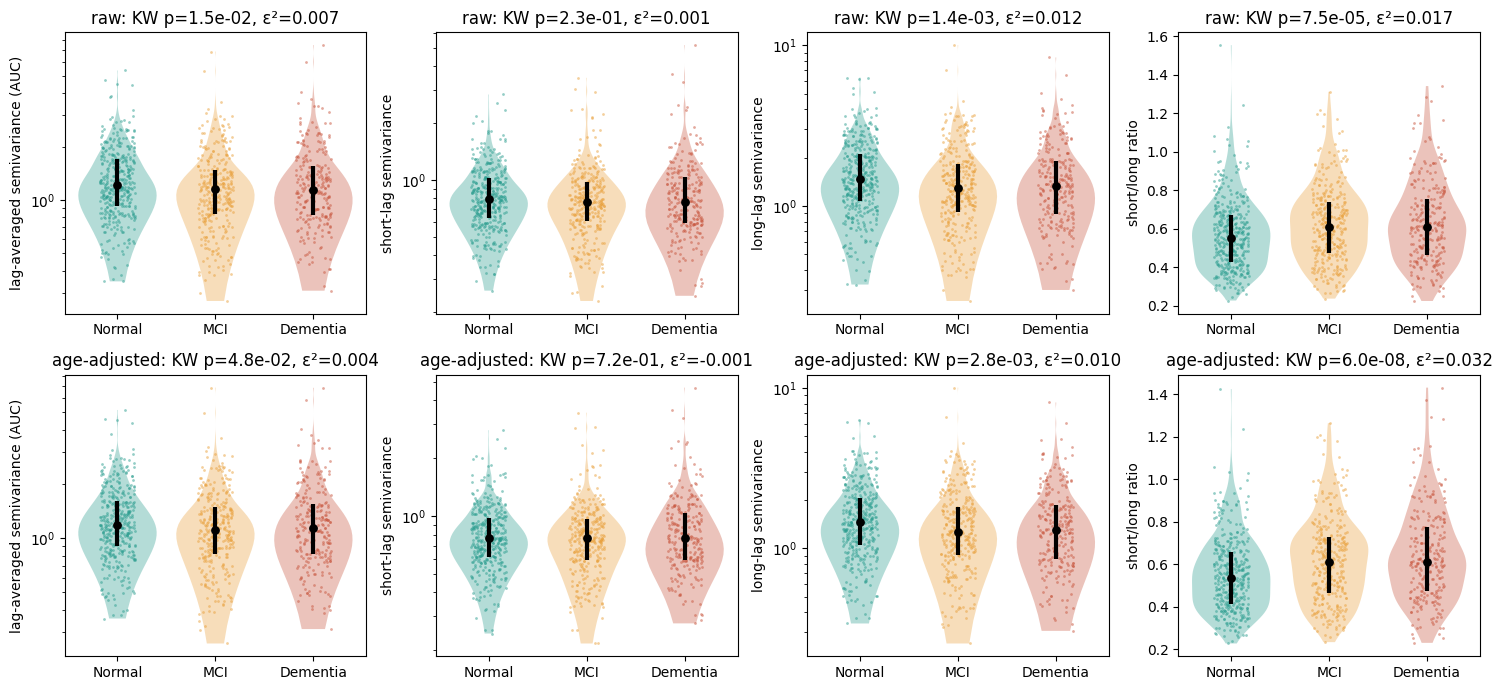

In [21]:
# Figure: endpoints by group (violin + points + black median), raw and age-adjusted (AJJ #81-82).
_show = ["AUC", "short", "long", "ratio"]
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for row, v in enumerate(VARIANTS):
    for ax, k in zip(axes[row], _show):
        c = compare_groups(ENDPOINTS[("L2", v)][k])
        violin_points(ax, ENDPOINTS[("L2", v)][k], ENDPOINT_LABELS[k] if ax is axes[row][0] or True else "",
                      f"{'raw' if v=='raw' else 'age-adjusted'}: KW p={c['p']:.1e}, ε²={c['eps2']:.3f}")
        if k != "ratio": ax.set_yscale("log")
fig.tight_layout(); savefig(fig, "F3_subject_endpoints"); plt.show()

## 11. Sensor level: neighbourhood semivariance and MNE cluster-based permutation tests (AJJ #46, #61-62, #96, #106, #108)

In [22]:
N_NEIGH = ADJ.sum(1)
def neighbourhood_semivariance(D2s):
    """V(j) = 1/(2 n_j) sum_{k in N(j)} d^2(X_j, X_k), N(j) = adjacent electrodes (frozen graph).
    Replaces Eq. 15 of the previous draft (mean dissimilarity with ALL other sensors)."""
    return 0.5 * (D2s * ADJ[None]).sum(2) / N_NEIGH[None]

NSV = {(m, v): {g: neighbourhood_semivariance(D2[(m, v)][g]) for g in (0, 1, 2)} for m in METRICS for v in VARIANTS}

T_THRESH_2 = None   # filled per test from the t distribution (p < 0.05, two-sided)
def cluster_tests(X_by_group, adjacency=ADJ_SPARSE, n_perm=N_PERM, tfce=False, seed=SEED):
    """X_by_group: dict g -> [n_g, n_features] (log-transformed to reduce skewness; permutation
    inference is exact regardless). Returns omnibus (F, 3 groups) and Normal vs Abnormal (t)."""
    from scipy.stats import f as fdist, t as tdist
    Xs = [np.log(X_by_group[g]) if np.all(X_by_group[g] > 0) else X_by_group[g] for g in (0, 1, 2)]
    n = [len(x) for x in Xs]
    from scipy.stats import f_oneway, ttest_ind
    _Fo = f_oneway(*Xs, axis=0).statistic; _to = np.abs(ttest_ind(np.concatenate(Xs[1:]), Xs[0], axis=0).statistic)
    thr_F = dict(start=0, step=max(np.nanmax(_Fo), 1e-3) / 100) if tfce else fdist.ppf(1 - ALPHA, 2, sum(n) - 3)
    F, clF, pF, _ = permutation_cluster_test(Xs, threshold=thr_F, n_permutations=n_perm, adjacency=adjacency,
                                             tail=1, seed=seed, out_type="mask", verbose=False)
    A, B = Xs[0], np.concatenate([Xs[1], Xs[2]])
    thr_t = dict(start=0, step=max(np.nanmax(_to), 1e-3) / 100) if tfce else tdist.ppf(1 - ALPHA / 2, len(A) + len(B) - 2)
    tv, clt, pt, _ = permutation_cluster_test([B, A], threshold=thr_t, n_permutations=n_perm, adjacency=adjacency,
                                              stat_fun=ttest_ind_no_p, tail=0, seed=seed, out_type="mask", verbose=False)
    def sig_mask(cl, p, shape):
        m = np.zeros(shape, bool)
        for c, pp in zip(cl, p):
            if pp < ALPHA: m |= np.asarray(c).reshape(shape)
        return m
    if tfce:   # with TFCE every feature is its own "cluster"
        mF, mt = np.asarray(pF).reshape(F.shape) < ALPHA, np.asarray(pt).reshape(tv.shape) < ALPHA
    else:
        mF, mt = sig_mask(clF, pF, F.shape), sig_mask(clt, pt, tv.shape)
    return dict(F=F, mask_F=mF, clusters_F=[(np.asarray(c).reshape(F.shape), p) for c, p in zip(clF, pF)] if not tfce else None,
                t=tv, mask_t=mt, clusters_t=[(np.asarray(c).reshape(tv.shape), p) for c, p in zip(clt, pt)] if not tfce else None,
                min_p_F=float(np.min(pF)) if len(pF) else 1.0, min_p_t=float(np.min(pt)) if len(pt) else 1.0)

CLUST = {}
import time
for m in METRICS:
    for v in VARIANTS:
        for tf in ((False, True) if m == "L2" else (False,)):     # TFCE only for the primary metric
            _t0 = time.time(); CLUST[(m, v, tf)] = cluster_tests(NSV[(m, v)], tfce=tf)
            print(f"  cluster test {m:12s} {v:13s} {'TFCE' if tf else 'mass'}: {time.time()-_t0:.1f} s")

rows = []
for (m, v, tf), r in CLUST.items():
    rows.append(dict(metric=m, variant=v, method="TFCE" if tf else "cluster mass",
                     n_sig_F=int(r["mask_F"].sum()), chans_F=", ".join(np.array(CH_LABELS)[r["mask_F"]]),
                     min_p_F=r["min_p_F"], n_sig_t=int(r["mask_t"].sum()),
                     chans_t=", ".join(np.array(CH_LABELS)[r["mask_t"]]), min_p_t=r["min_p_t"]))
T4 = save_table(pd.DataFrame(rows), "T4_sensor_cluster_tests", float_format="%.4f")
print(T4.to_string(index=False))
for (m, v, tf), r in CLUST.items():
    tag = {"L2": "LTwo"}.get(m, re.sub("[^A-Za-z]", "", m)) + ("Raw" if v == "raw" else "Adj") + ("Tfce" if tf else "Clu")
    macro(f"nSigF{tag}", int(r["mask_F"].sum())); macro(f"nSigT{tag}", int(r["mask_t"].sum()))
    macro(f"chF{tag}", ", ".join(np.array(CH_LABELS)[r["mask_F"]]) or "none")
    macro(f"chT{tag}", ", ".join(np.array(CH_LABELS)[r["mask_t"]]) or "none")
    macro(f"minpF{tag}", fmt_p(r["min_p_F"])); macro(f"minpT{tag}", fmt_p(r["min_p_t"]))

  cluster test L2           raw           mass: 5.6 s
  cluster test L2           raw           TFCE: 169.7 s
  cluster test L2           age-adjusted  mass: 5.1 s
  cluster test L2           age-adjusted  TFCE: 209.8 s
  cluster test Wasserstein  raw           mass: 4.8 s
  cluster test Wasserstein  age-adjusted  mass: 4.7 s
  cluster test Mahalanobis  raw           mass: 5.5 s
  cluster test Mahalanobis  age-adjusted  mass: 4.8 s
  cluster test Fisher-Rao   raw           mass: 4.8 s
  cluster test Fisher-Rao   age-adjusted  mass: 4.7 s
     metric      variant       method  n_sig_F                                                                      chans_F  min_p_F  n_sig_t                                                                      chans_t  min_p_t
         L2          raw cluster mass        4                                                               T4, P4, T6, O2   0.0124        4                                                               T4, P4, T6, O2   0.0186


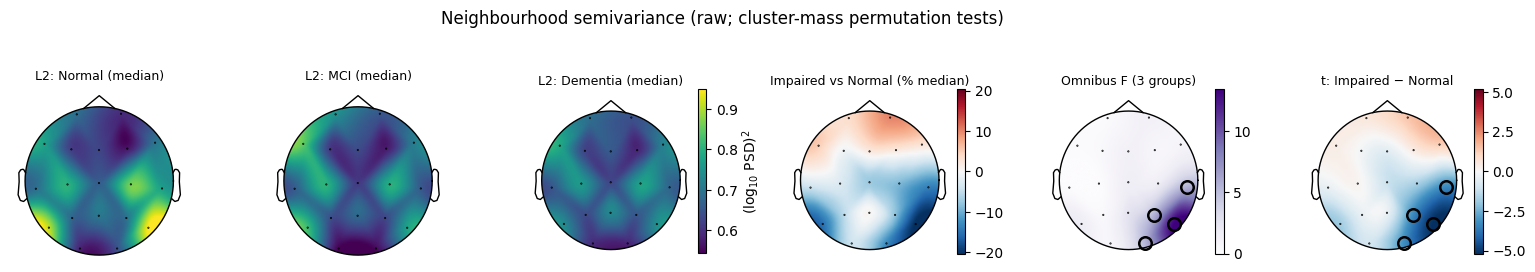

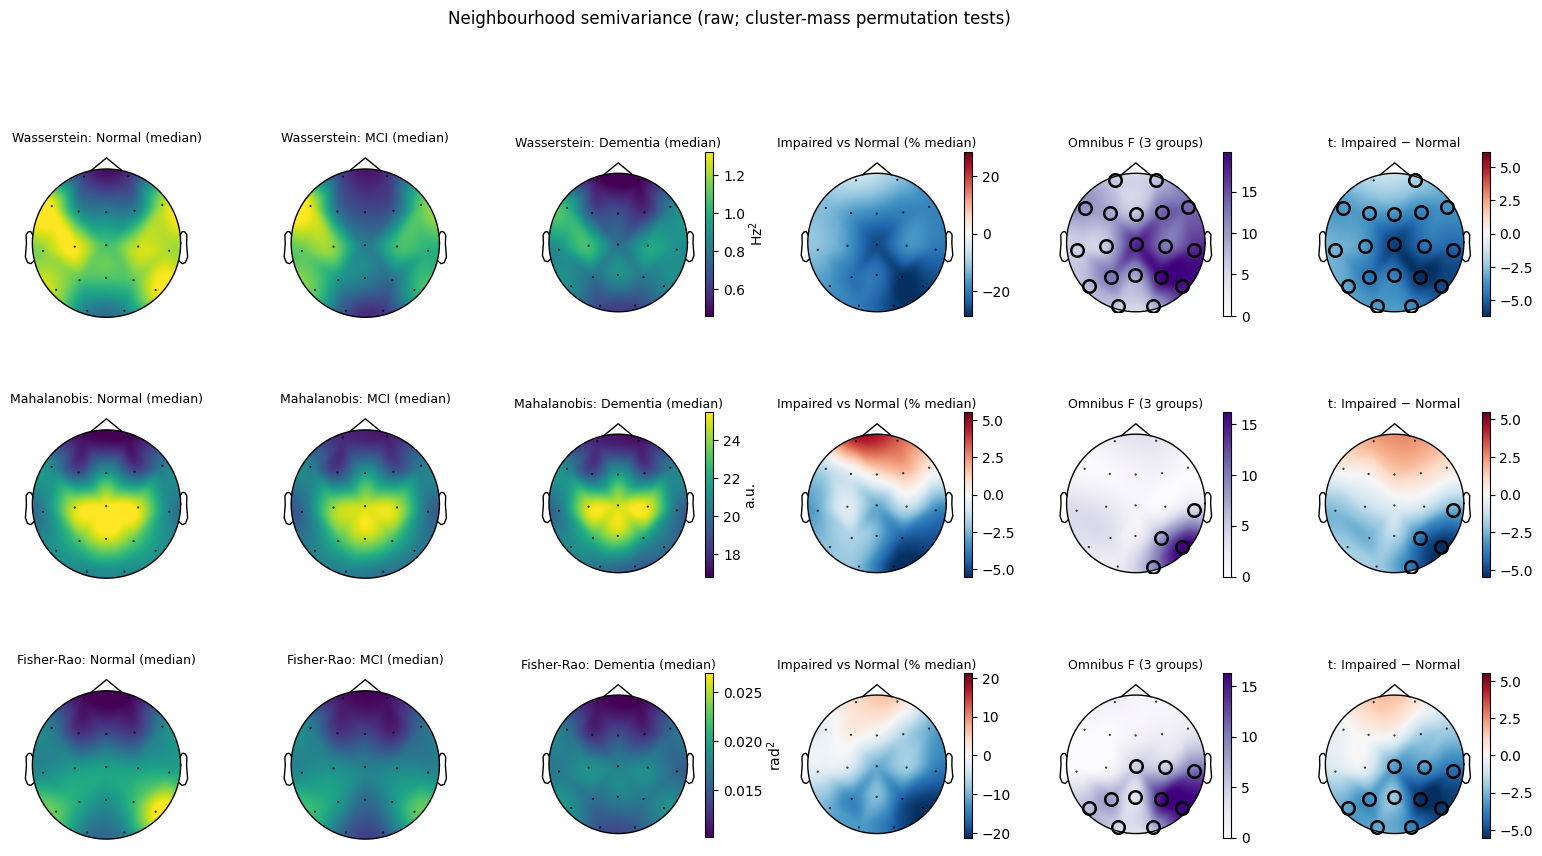

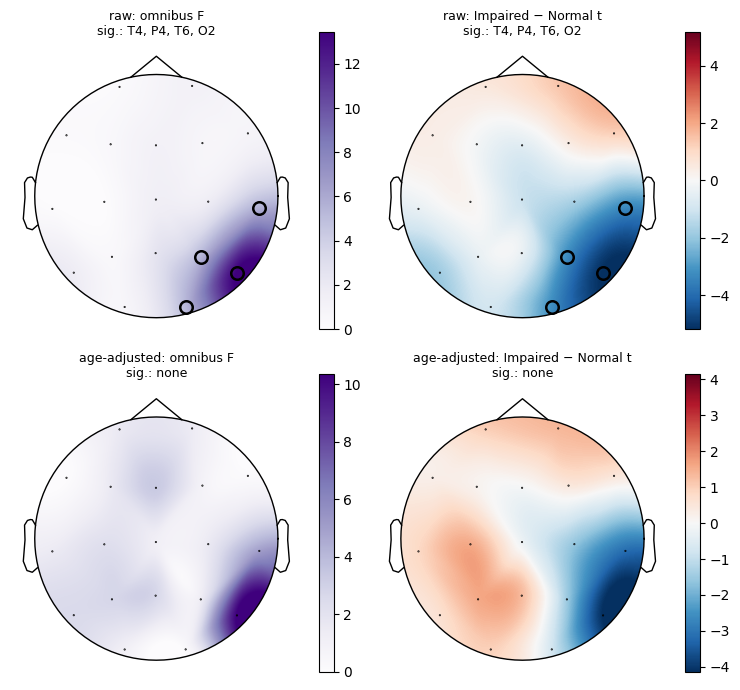

In [23]:
MASK_PARAMS = dict(marker="o", markerfacecolor="none", markeredgecolor="k", markersize=9, markeredgewidth=1.8)
def topo(ax, values, vlim, cmap, title, mask=None):
    im, _ = mne.viz.plot_topomap(values, POS2D, axes=ax, show=False, cmap=cmap, vlim=vlim, sphere=SPHERE_TOPO,
                                 contours=0, sensors=True, mask=mask, mask_params=MASK_PARAMS, extrapolate="head")
    ax.set_title(title, fontsize=9); return im

def topo_grid(metrics, variant="raw", tfce=False, name="F4_sensor_topographies"):
    """Rows = metrics. Columns: group medians (shared scale) -> % difference Abnormal vs Normal ->
    omnibus F (circles = significant) -> Normal vs Abnormal t (circles = significant). AJJ #106."""
    fig, axes = plt.subplots(len(metrics), 6, figsize=(19, 3.2 * len(metrics)), squeeze=False,
                             gridspec_kw=dict(wspace=0.45))
    for i, m in enumerate(metrics):
        X = NSV[(m, variant)]; med = {g: np.median(X[g], 0) for g in (0, 1, 2)}
        lo, hi = min(v.min() for v in med.values()), max(v.max() for v in med.values())
        for j, g in enumerate((0, 1, 2)):
            im = topo(axes[i, j], med[g], (lo, hi), "viridis", f"{m}: {GROUP_NAMES[g]} (median)")
        plt.colorbar(im, ax=axes[i, 2], fraction=0.046, pad=0.02).set_label(METRIC_UNITS[m], labelpad=2)
        ab = np.median(np.concatenate([X[1], X[2]]), 0)
        pct = 100 * (ab - med[0]) / med[0]; lim = np.abs(pct).max()
        im = topo(axes[i, 3], pct, (-lim, lim), "RdBu_r", "Impaired vs Normal (% median)")
        plt.colorbar(im, ax=axes[i, 3], fraction=0.046, pad=0.02)
        r = CLUST[(m, variant, tfce)]
        im = topo(axes[i, 4], r["F"], (0, max(r["F"].max(), 1)), "Purples", "Omnibus F (3 groups)", mask=r["mask_F"])
        plt.colorbar(im, ax=axes[i, 4], fraction=0.046, pad=0.02)
        lim = np.abs(r["t"]).max()
        im = topo(axes[i, 5], r["t"], (-lim, lim), "RdBu_r", "t: Impaired − Normal", mask=r["mask_t"])
        plt.colorbar(im, ax=axes[i, 5], fraction=0.046, pad=0.02)
    fig.suptitle(f"Neighbourhood semivariance ({variant}; {'TFCE' if tfce else 'cluster-mass'} permutation tests)", y=1.0)
    savefig(fig, name); plt.show()

topo_grid(["L2"], name="F4_sensor_topographies_L2")
topo_grid(["Wasserstein", "Mahalanobis", "Fisher-Rao"], name="S_sensor_topographies_alt_metrics")

# 2 x 2 grid raw vs age-adjusted (AJJ #96)
fig, axes = plt.subplots(2, 2, figsize=(7.5, 7))
for i, v in enumerate(VARIANTS):
    r = CLUST[("L2", v, False)]
    chF = ", ".join(np.array(CH_LABELS)[r["mask_F"]]) or "none"; cht = ", ".join(np.array(CH_LABELS)[r["mask_t"]]) or "none"
    im = topo(axes[i, 0], r["F"], (0, max(r["F"].max(), 1)), "Purples", f"{v}: omnibus F\nsig.: {chF}", r["mask_F"])
    plt.colorbar(im, ax=axes[i, 0], fraction=0.046)
    lim = np.abs(r["t"]).max()
    im = topo(axes[i, 1], r["t"], (-lim, lim), "RdBu_r", f"{v}: Impaired − Normal t\nsig.: {cht}", r["mask_t"])
    plt.colorbar(im, ax=axes[i, 1], fraction=0.046)
fig.tight_layout(); savefig(fig, "F5_sensor_raw_vs_age"); plt.show()

In [24]:
# Supplementary: per-electrode Kruskal-Wallis / Mann-Whitney with BH-FDR (former Table 14).
rows = []
for v in VARIANTS:
    X = NSV[("L2", v)]
    p_kw = np.array([kruskal(X[0][:, c], X[1][:, c], X[2][:, c])[1] for c in range(N_CH)])
    p_mw = np.array([mannwhitneyu(X[0][:, c], np.concatenate([X[1][:, c], X[2][:, c]]))[1] for c in range(N_CH)])
    for c, q1, q2, a, b in zip(CH_LABELS, bh_fdr(p_kw), bh_fdr(p_mw), p_kw, p_mw):
        rows.append(dict(variant=v, channel=c, p_KW=a, q_KW=q1, p_MW=b, q_MW=q2))
save_table(pd.DataFrame(rows), "S_electrode_fdr_tests", float_format="%.4f")

,variant,channel,p_KW,q_KW,p_MW,q_MW
0,raw,Fp1,0.784312,0.827885,4.870897e-01,0.661050
1,raw,Fp2,0.265994,0.561543,1.113005e-01,0.264339
2,raw,F7,0.649206,0.725583,7.404289e-01,0.781564
3,raw,F3,0.830307,0.830307,9.671419e-01,0.967142
4,raw,Fz,0.535283,0.725583,7.034131e-01,0.781564
5,raw,F4,0.625214,0.725583,5.526720e-01,0.699737
6,raw,F8,0.426504,0.725583,1.924236e-01,0.406228
7,raw,T3,0.606193,0.725583,3.823132e-01,0.558766
8,raw,C3,0.567721,0.725583,3.684385e-01,0.558766
9,raw,Cz,0.207002,0.491630,1.078011e-01,0.264339


## 12. Spectral-domain cluster test on age-residualized log-PSD (3-D input; AJJ #62)

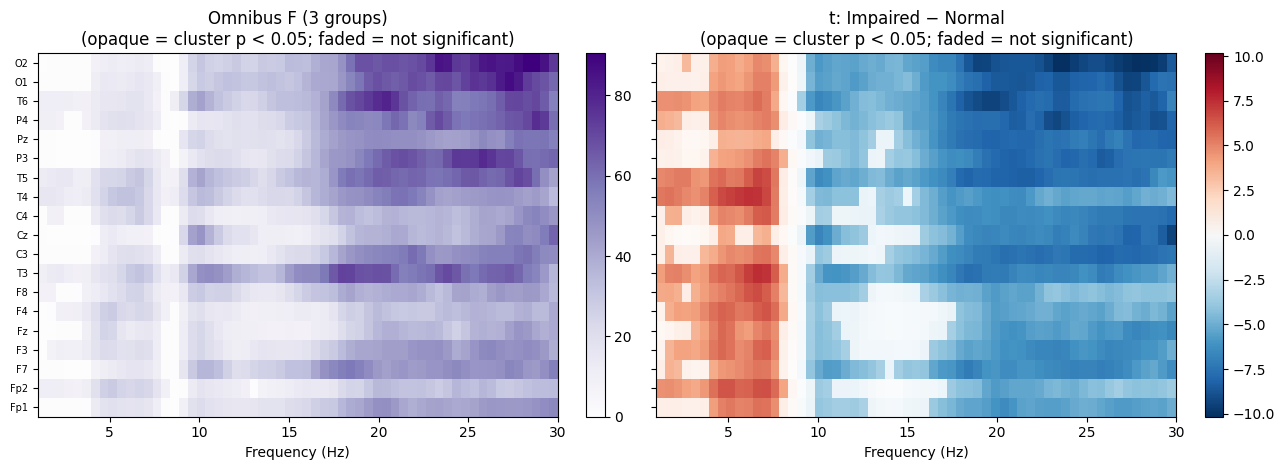

               test     p  f_lo  f_hi                                                                     channels  sign  n_features
Impaired - Normal t 0.001   9.0  30.0 Fp1, Fp2, F7, F3, Fz, F4, F8, T3, C3, Cz, C4, T4, T5, P3, Pz, P4, T6, O1, O2  -1.0         706
Impaired - Normal t 0.001   1.0   8.0 Fp1, Fp2, F7, F3, Fz, F4, F8, T3, C3, Cz, C4, T4, T5, P3, Pz, P4, T6, O1, O2   1.0         208
          omnibus F 0.001   1.0  30.0 Fp1, Fp2, F7, F3, Fz, F4, F8, T3, C3, Cz, C4, T4, T5, P3, Pz, P4, T6, O1, O2   1.0        1021


In [25]:
FSTEP = max(1, int(round(0.5 / np.diff(GRID).mean())))          # 0.5-Hz resolution to save time
FIDX = np.arange(0, T, FSTEP); F3D = GRID[FIDX]
PSD_ADJ = {g: np.stack([(PHI @ Z.T)[FIDX] for Z in COEFS_AGE[g]]) for g in (0, 1, 2)}   # [n, f, 19]
ADJ_3D = combine_adjacency(len(F3D), ADJ_SPARSE)
from scipy.stats import f as _fdist, t as _tdist
_n = [len(PSD_ADJ[g]) for g in (0, 1, 2)]
F_s, clF_s, pF_s, _ = permutation_cluster_test([PSD_ADJ[g] for g in (0, 1, 2)], threshold=_fdist.ppf(0.999, 2, sum(_n) - 3),
                                                n_permutations=N_PERM_3D, adjacency=ADJ_3D, tail=1, seed=SEED,
                                                out_type="mask", verbose=False)
_A, _B = PSD_ADJ[0], np.concatenate([PSD_ADJ[1], PSD_ADJ[2]])
t_s, clt_s, pt_s, _ = permutation_cluster_test([_B, _A], threshold=_tdist.ppf(1 - 0.0005, len(_A) + len(_B) - 2),
                                                n_permutations=N_PERM_3D, adjacency=ADJ_3D, stat_fun=ttest_ind_no_p,
                                                tail=0, seed=SEED, out_type="mask", verbose=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for a, S, cl, pv, cmap, ttl in ((ax[0], F_s, clF_s, pF_s, "Purples", "Omnibus F (3 groups)"),
                                 (ax[1], t_s, clt_s, pt_s, "RdBu_r", "t: Impaired − Normal")):
    vlim = (0, S.max()) if cmap == "Purples" else (-np.abs(S).max(), np.abs(S).max())
    msk = np.zeros_like(S, bool)
    for c, p in zip(cl, pv):
        if p < ALPHA: msk |= c
    ext = [F3D[0], F3D[-1], -0.5, N_CH - 0.5]
    a.imshow(S.T, aspect="auto", origin="lower", cmap=cmap, vmin=vlim[0], vmax=vlim[1], extent=ext, alpha=0.25)
    im = a.imshow(np.ma.masked_where(~msk.T, S.T), aspect="auto", origin="lower", cmap=cmap,
                  vmin=vlim[0], vmax=vlim[1], extent=ext)
    a.set_yticks(range(N_CH)); a.set_yticklabels(CH_LABELS, fontsize=7); a.set_xlabel("Frequency (Hz)")
    a.set_title(f"{ttl}\n(opaque = cluster p < 0.05; faded = not significant)"); plt.colorbar(im, ax=a, fraction=0.04)
fig.tight_layout(); savefig(fig, "F6_spectral_cluster_test"); plt.show()
rows = []
for name, cl, pv, S in (("omnibus F", clF_s, pF_s, F_s), ("Impaired - Normal t", clt_s, pt_s, t_s)):
    for c, p in zip(cl, pv):
        if p < ALPHA:
            fi, ci = np.where(c)
            rows.append(dict(test=name, p=p, f_lo=F3D[fi].min(), f_hi=F3D[fi].max(),
                             channels=", ".join(np.array(CH_LABELS)[np.unique(ci)]), sign=np.sign(S[c].mean())))
_T5 = pd.DataFrame(rows)
if len(_T5):
    _T5["n_features"] = [int(c.sum()) for name, cl, pv, S in (("omnibus F", clF_s, pF_s, F_s), ("Impaired - Normal t", clt_s, pt_s, t_s))
                         for c, p in zip(cl, pv) if p < ALPHA]
    _T5 = _T5.sort_values(["test", "n_features"], ascending=[True, False]).groupby("test").head(5)
save_table(pd.DataFrame(rows), "S_spectral_clusters_all", float_format="%.3f")
T5 = save_table(_T5, "T5_spectral_clusters", float_format="%.3f")
print(T5.to_string(index=False))
macro("nSpectralClusters", len(T5))
for name, tag in (("Impaired - Normal t", "T"), ("omnibus F", "F")):
    d = pd.DataFrame(rows)
    if len(d):
        d = d[d.test == name]
    for sgn, s in ((-1.0, "Neg"), (1.0, "Pos")):
        dd = d[d.sign == sgn] if len(d) else d
        if len(dd):
            r = dd.loc[(dd.f_hi - dd.f_lo).idxmax()]
            macro(f"spec{tag}{s}Lo", r.f_lo, ".1f"); macro(f"spec{tag}{s}Hi", r.f_hi, ".1f")
            macro(f"spec{tag}{s}nCh", len(r.channels.split(", "))); macro(f"spec{tag}{s}P", fmt_p(r.p))
        else:
            for k in ("Lo", "Hi", "nCh", "P"): macro(f"spec{tag}{s}{k}", "NA")

## 13. Sensitivity analyses (supplement)

In [26]:
def endpoint_row(D2g, label, D=DIST_GC, keep=None):
    if keep is not None:
        D2g = {g: D2g[g][keep[g]] for g in (0, 1, 2)}
    vals, _, _ = endpoint_table(D2g, D)
    return results_table({k: vals[k] for k in ("AUC", "short", "ratio", "sill")}, label)

SENS = [RES_MAIN[RES_MAIN.endpoint.isin([ENDPOINT_LABELS[k] for k in ("AUC", "short", "ratio", "sill")])]]
SENS.append(endpoint_row(D2[("L2", "raw")], "3-D chord distance", DIST_CHORD))
SENS.append(endpoint_row(D2[("L2", "raw")], "2-D topomap distance", DIST_2D))
for k, D2g in D2_SENS.items(): SENS.append(endpoint_row(D2g, k))
for m in ("Wasserstein", "Mahalanobis", "Fisher-Rao"):
    for v in VARIANTS: SENS.append(endpoint_row(D2[(m, v)], f"{m}, {v}"))
if min(IN_SUPPORT[g].sum() for g in (0, 1, 2)) >= 5:
    SENS.append(endpoint_row(D2[("L2", "age-adjusted")], "age-adjusted, common age support", keep=IN_SUPPORT))
# Spatial detrending (linear trend in the 3-D unit-sphere coordinates removed from every coefficient):
_X = np.column_stack([np.ones(N_CH), UNIT]); P_DET = np.eye(N_CH) - _X @ np.linalg.pinv(_X)
SENS.append(endpoint_row(d2_stack({g: [P_DET @ Z for Z in COEFS[g]] for g in (0, 1, 2)}, "L2"), "linear spatial trend removed"))
TS = pd.concat(SENS, ignore_index=True)
_SENS_TAG = {"3-D chord distance": "Chord", "2-D topomap distance": "TwoD", "PSD bandwidth 2 Hz": "Bw",
             "all clean epochs": "AllEp", "Wasserstein, raw": "Wass", "Mahalanobis, raw": "Maha",
             "Fisher-Rao, raw": "Fr", "age-adjusted, common age support": "Support",
             "linear spatial trend removed": "Detr"}
for lab, tg in _SENS_TAG.items():
    for k, kk in (("AUC", "Auc"), ("short", "Short"), ("ratio", "Ratio"), ("sill", "Sill")):
        r = TS[(TS.analysis == lab) & (TS.endpoint == ENDPOINT_LABELS[k])]
        macro(f"s{tg}{kk}P", fmt_p(r.p.iloc[0]) if len(r) else "NA")
        macro(f"s{tg}{kk}Rho", format(r.rho.iloc[0], "+.3f") if len(r) else "NA")
save_table(TS[["analysis", "endpoint", "H", "p", "eps2", "rho", "delta_ND", "p_NA", "delta_NA"]], "S_sensitivity_endpoints", float_format="%.3g")
print(TS[["analysis", "endpoint", "p", "eps2", "rho"]].round(4).to_string(index=False))

# Age-matched Normal vs Dementia (greedy 1:1, caliper 3 years) on the primary endpoints.
def match_by_age(a0, a1, caliper=3.0):
    used, pairs = set(), []
    for i in np.argsort(a1):
        d = np.abs(a0 - a1[i]); d[list(used)] = np.inf; j = int(np.argmin(d))
        if d[j] <= caliper: used.add(j); pairs.append((j, i))
    return np.array(pairs)
PAIRS_ND = match_by_age(AGES[0], AGES[2]); macro("nMatchedPairs", len(PAIRS_ND))
rows = []
for k in ("AUC", "short", "ratio"):
    a = ENDPOINTS[("L2", "raw")][k][0][PAIRS_ND[:, 0]]; b = ENDPOINTS[("L2", "raw")][k][2][PAIRS_ND[:, 1]]
    p = mannwhitneyu(a, b)[1]; rows.append(dict(endpoint=ENDPOINT_LABELS[k], median_Normal=np.median(a),
                                                median_Dementia=np.median(b), p=p, delta=cliffs_delta(b, a)))
    macro(f"pMatched{_key[k]}", fmt_p(p)); macro(f"dMatched{_key[k]}", cliffs_delta(b, a), "+.2f")
save_table(pd.DataFrame(rows), "S_age_matched", float_format="%.3g")

                        analysis                        endpoint      p    eps2     rho
                         L2, raw lag-averaged semivariance (AUC) 0.0146  0.0067 -0.0737
                         L2, raw          short-lag semivariance 0.2252  0.0010 -0.0398
                         L2, raw                short/long ratio 0.0001  0.0175  0.1279
                         L2, raw              sill (exponential) 0.0000  0.0184 -0.1337
              3-D chord distance lag-averaged semivariance (AUC) 0.0434  0.0044 -0.0605
              3-D chord distance          short-lag semivariance 0.2252  0.0010 -0.0398
              3-D chord distance                short/long ratio 0.0002  0.0151  0.1187
              3-D chord distance              sill (exponential) 0.0000  0.0206 -0.1304
            2-D topomap distance lag-averaged semivariance (AUC) 0.0167  0.0064 -0.0705
            2-D topomap distance          short-lag semivariance 0.2252  0.0010 -0.0398
            2-D topomap distance

,endpoint,median_Normal,median_Dementia,p,delta
0,lag-averaged semivariance (AUC),1.172984,1.091484,0.105759,-0.109917
1,short-lag semivariance,0.776934,0.750898,0.374593,-0.060357
2,short/long ratio,0.548572,0.607946,0.007601,0.181356


In [27]:
# Supplement: model comparison at subject level (Friedman on RMSE, % best model by AICc).
rows, pct = [], []
for g in (0, 1, 2):
    R = []; best = Counter()
    for s in range(len(D2[("L2", "raw")][g])):
        cen, gam, cnt = variogram(D2[("L2", "raw")][g][[s]], DIST_GC, NBINS_SUBJECT)
        fits = [fit_variogram(m, cen, gam, cnt) for m in MODELS]
        if all(fits):
            R.append([f["rmse"] for f in fits]); best[min(fits, key=lambda f: f["aicc"])["model"]] += 1
    R = np.array(R); chi, p = friedmanchisquare(*R.T)
    rows.append(dict(group=GROUP_NAMES[g], n=len(R), chi2=chi, p=p))
    pct.append({"group": GROUP_NAMES[g], **{m: 100 * best[m] / max(len(R), 1) for m in MODELS}})
save_table(pd.DataFrame(rows), "S_friedman_models", float_format="%.3g")
save_table(pd.DataFrame(pct), "S_pct_best_model", float_format="%.1f")

# Supplement: 3-ROI analysis on the neighbourhood semivariance (one paragraph in the main text).
rows = []
for v in VARIANTS:
    for r_, idx in REGION3_IDX.items():
        vals = {g: NSV[("L2", v)][g][:, idx].mean(1) for g in (0, 1, 2)}
        c = compare_groups(vals)
        rows.append(dict(variant=v, ROI=f"{r_} ({len(idx)})", **{GROUP_NAMES[g]: c["med"][g] for g in (0, 1, 2)},
                         rho=c["rho"], p=c["p"], eps2=c["eps2"]))
TR = pd.DataFrame(rows); TR["q"] = np.concatenate([bh_fdr(TR[TR.variant == v].p) for v in VARIANTS])
save_table(TR, "S_roi", float_format="%.3g"); print(TR.round(4).to_string(index=False))

     variant           ROI  Normal    MCI  Dementia     rho      p    eps2      q
         raw  Anterior (7)  0.6929 0.7371    0.7374  0.0293 0.6347 -0.0011 0.6347
         raw   Central (5)  0.8013 0.7598    0.7623 -0.0535 0.1383  0.0020 0.2075
         raw Posterior (7)  0.7580 0.7071    0.7012 -0.0705 0.0334  0.0049 0.1002
age-adjusted  Anterior (7)  0.7025 0.7209    0.7573  0.0408 0.4300 -0.0003 0.7968
age-adjusted   Central (5)  0.7732 0.7494    0.7441 -0.0249 0.6367 -0.0011 0.7968
age-adjusted Posterior (7)  0.7079 0.7056    0.7289 -0.0095 0.7968 -0.0016 0.7968


## 14. Benchmark against classical qEEG features (supplement)

In [28]:
BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30)}
ANT = [CH_LABELS.index(c) for c in REGIONS3["Anterior"]]; POST = [CH_LABELS.index(c) for c in REGIONS3["Posterior"]]
def classical(S):
    bm = lambda lo, hi: S[:, (GRID >= lo) & (GRID < hi)].mean(1)
    d = {f"{b}": bm(*r).mean() for b, r in BANDS.items()}; a = bm(*BANDS["alpha"])
    d["alpha gradient (post-ant)"] = a[POST].mean() - a[ANT].mean()
    m = (GRID >= 7) & (GRID <= 13); d["posterior PAF (Hz)"] = float(GRID[m][np.argmax(S[POST][:, m].mean(0))])
    return d
CLASS = pd.DataFrame([classical(S) for g in (0, 1, 2) for S in SUBJECTS[g]])
CLASS["group"] = np.concatenate([np.full(len(SUBJECTS[g]), g) for g in (0, 1, 2)])
for k in ("AUC", "short", "ratio"):
    CLASS[k] = np.concatenate([ENDPOINTS[("L2", "raw")][k][g] for g in (0, 1, 2)])
cor = pd.DataFrame({k: [spearmanr(CLASS[k], CLASS[c])[0] for c in list(BANDS) + ["alpha gradient (post-ant)", "posterior PAF (Hz)"]]
                    for k in ("AUC", "short", "ratio")}, index=list(BANDS) + ["alpha gradient (post-ant)", "posterior PAF (Hz)"])
save_table(cor.reset_index().rename(columns={"index": "classical feature"}), "S_classical_correlations")
print(cor.round(3))
macro("rhoRatioGradient", cor.loc["alpha gradient (post-ant)", "ratio"], "+.2f")
macro("rhoAucGradient", cor.loc["alpha gradient (post-ant)", "AUC"], "+.2f")

                             AUC  short  ratio
delta                     -0.484 -0.471  0.207
theta                     -0.419 -0.401  0.159
alpha                     -0.116 -0.142 -0.072
beta                      -0.079 -0.123 -0.093
alpha gradient (post-ant)  0.688  0.393 -0.803
posterior PAF (Hz)         0.258  0.221 -0.182


'+0.69'

## 15. Export manuscript macros

In [29]:
with open(os.path.join(OUT_DIR, "results_macros.tex"), "w") as f:
    f.write("% Auto-generated by Geoestadistica_Funcional_EEG_v23.ipynb -- do not edit by hand\n")
    for k, v in sorted(MACROS.items()):
        f.write(f"\\newcommand{{\\{k}}}{{{v}}}\n")
print(f"{len(MACROS)} macros written to", os.path.join(OUT_DIR, "results_macros.tex"))
print("Tables:", sorted(os.listdir(TAB_DIR))); print("Figures:", sorted(os.listdir(FIG_DIR)))

366 macros written to /content/drive/MyDrive/Carpeta_Doctorado/data_completa/caueeg-dataset/results_v23/results_macros.tex
Tables: ['S_age_matched.csv', 'S_age_matched.tex', 'S_classical_correlations.csv', 'S_classical_correlations.tex', 'S_electrode_fdr_tests.csv', 'S_electrode_fdr_tests.tex', 'S_event_ec_closers.csv', 'S_event_ec_closers.tex', 'S_event_labels.csv', 'S_event_labels.tex', 'S_friedman_models.csv', 'S_friedman_models.tex', 'S_group_level_all_metrics.csv', 'S_group_level_all_metrics.tex', 'S_group_level_all_models.csv', 'S_group_level_all_models.tex', 'S_inclusion_flow.csv', 'S_inclusion_flow.tex', 'S_pct_best_model.csv', 'S_pct_best_model.tex', 'S_roi.csv', 'S_roi.tex', 'S_sensitivity_endpoints.csv', 'S_sensitivity_endpoints.tex', 'S_spectral_clusters_all.csv', 'S_spectral_clusters_all.tex', 'T1_sample_characteristics.csv', 'T1_sample_characteristics.tex', 'T2_group_level_common_model.csv', 'T2_group_level_common_model.tex', 'T3_subject_level_endpoints.csv', 'T3_subject_

In [30]:
import shutil
shutil.make_archive("/content/results_v23", "zip", OUT_DIR)
from google.colab import files
files.download("/content/results_v23.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>